---
# Parte 1. Entendimiento del negocio

## 📖 La historia
En el salto ecuestre los caballos suben de altura poco a poco durante su carrera. El nivel élite son las pruebas de **160 cm**, y la mayoría de los caballos llega ahí, si llega, entre los 9 y los 10 años. Pero las decisiones caras (comprar, vender, invertir en entrenamiento, usar para cría) se toman **mucho antes**, y hoy dependen sobre todo del ojo del entrenador.

Somos analistas de un criadero que quiere decidir en qué caballos jóvenes invertir, y nos preguntan:

> ### ❓ Con el historial de competencias de un caballo a los 8 años, ¿podemos predecir si su carrera llegará al nivel élite (un recorrido limpio a 160 cm)?

## ⚠️ Alcance: el resultado es del binomio, no solo del caballo
Cada recorrido es producto del **binomio jinete–caballo**: técnica, experiencia y mentalidad del jinete, más las decisiones del equipo sobre a qué concursos llevar al caballo. La base **no identifica al jinete**, así que este proyecto **no mide el talento "puro" del caballo**. Lo que predice es algo más práctico: **la trayectoria de la carrera a partir del récord visible**, que es justo lo que puede revisar un comprador al evaluar un caballo de 8 años. Ese récord ya trae incluido el efecto del jinete y del equipo.

## 🎯 Objetivos medibles
Es un problema de **clasificación supervisada binaria** con target `champion` (1 = llegó a 160 cm limpio, 0 = no llegó).

| # | Objetivo | Meta |
|---|---|---|
| 1 | Ordenar bien a los caballos por probabilidad de llegar a la élite | **AUC-ROC ≥ 0.80** en validación cruzada |
| 2 | No dejar ir a los futuros campeones (la clase minoritaria) | **Recall ≥ 0.65** |
| 3 | Aportar algo más que el "ojo del entrenador" | **Superar a la regla simple** "si ya saltó alto, llegará" en AUC y F1 |
| 4 | Que el resultado no dependa de la partición | Desviación estándar baja en la **validación cruzada de 10 pliegues** |
| 5 | Que el modelo no haga trampa | **Cero fuga de datos**: solo se usa lo que se sabría del caballo a los 8 años |

**Costo de cada error.** Un **falso positivo** (creer que llegará y no llega) implica invertir en un caballo que no rinde. Un **falso negativo** implica vender o descartar a un futuro caballo de élite. Por eso no basta con la exactitud.

---
# 0. Preparación

 **Funciones auxiliares del curso** (visualización, machine learning y clasificación). 

| Función | ¿Para qué sirve? |
|---|---|
| `plot_distributions`, `plot_frequencies`, `plot_correlation_matrix` | Exploración de variables |
| `escalar`, `plot_curva_k`, `plot_curva_complejidad`, `plot_importancias`, `plot_arbol` | Modelos de scikit-learn |
| `ajustar_logit`, `razon_de_momios`, `evaluar_clasificador`, `plot_tasa_por_categoria`, `plot_matriz_confusion`, `plot_curva_roc`, `plot_metricas_por_umbral`, `plot_rfecv_clasificacion` | Clasificación |
| `evaluar_completo(nombre, y_real, y_pred, y_proba)` | **Nueva:** `evaluar_clasificador` + exactitud balanceada y AUC |
| `plot_region(modelo, X, y, columnas, titulo)` | **Nueva:** región de clasificación con las 2 mejores variables |
| `RecortadorIQR` | **Nueva:** recorta outliers con los límites IQR **calculados solo con train** (se puede meter en un `Pipeline`) |

In [1]:
# Funciones auxiliares de visualización
import numpy as np
import plotly.express as px
import plotly.graph_objects as go


def plot_distributions(df, columns, nbins=30):
    """Histograma con boxplot marginal para cada variable numérica."""
    for col in columns:
        fig = px.histogram(
            df,
            x=col,
            nbins=nbins,
            marginal='box',
            opacity=0.7,
            title=f'Distribución de {col}'
        )
        fig.update_layout(bargap=0.2)
        fig.show()


def plot_frequencies(df, columns, top_n=None):
    """Gráfica de barras con la frecuencia de cada categoría (top_n limita a las más comunes)."""
    for col in columns:
        freq = df[col].value_counts()
        if top_n:
            freq = freq.head(top_n)
        freq_df = freq.rename_axis(col).reset_index(name='Frecuencia')

        title = f'Frecuencias de {col}'
        if top_n and df[col].nunique() > top_n:
            title += f' (top {top_n})'

        fig = px.bar(freq_df, x=col, y='Frecuencia', title=title)
        fig.update_layout(xaxis={'categoryorder': 'total descending'})
        fig.show()


def plot_correlation_matrix(df, columns):
    """Mapa de calor con la correlación de Pearson entre las variables numéricas."""
    corr = df[columns].corr().round(2)
    fig = px.imshow(
        corr,
        text_auto=True,
        color_continuous_scale='RdBu_r',
        zmin=-1,
        zmax=1,
        title='Matriz de Correlación'
    )
    fig.update_layout(width=750, height=650)
    fig.show()


def plot_pairplot(df, columns, color=None):
    """Matriz de dispersión (pairplot) entre las variables numéricas."""
    fig = px.scatter_matrix(
        df,
        dimensions=columns,
        color=color,
        title='Pairplot de Variables Numéricas',
        labels={col: col.capitalize() for col in columns}
    )
    fig.update_layout(width=1200, height=1200, title_font_size=20)
    fig.update_traces(diagonal_visible=True)
    fig.show()


def plot_simple_regression(x, y, results):
    """Dispersión de una variable vs el objetivo con la recta ajustada por un OLS de 1 variable."""
    b0, b1 = results.params.iloc[0], results.params.iloc[1]
    x_name = getattr(x, 'name', None) or 'x'
    y_name = getattr(y, 'name', None) or 'y'
    x_line = np.linspace(np.min(x), np.max(x), 100)

    fig = px.scatter(
        x=np.asarray(x),
        y=np.asarray(y),
        opacity=0.6,
        labels={'x': x_name, 'y': y_name},
        title=f'{y_name} = {b0:.2f} + ({b1:.4f}) · {x_name}',
        template='plotly_white'
    )
    fig.add_trace(go.Scatter(
        x=x_line,
        y=b0 + b1 * x_line,
        mode='lines',
        name='Recta OLS',
        line=dict(color='red', width=3)
    ))
    fig.show()


def plot_actual_vs_predicted(y_true, y_pred, title='Real vs Predicho'):
    """Valores reales vs predichos; un modelo perfecto cae sobre la diagonal roja."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    lo = min(y_true.min(), y_pred.min())
    hi = max(y_true.max(), y_pred.max())

    fig = px.scatter(
        x=y_true,
        y=y_pred,
        opacity=0.5,
        labels={'x': 'Valor real', 'y': 'Valor predicho'},
        title=title,
        template='plotly_white'
    )
    fig.add_shape(
        type='line', x0=lo, y0=lo, x1=hi, y1=hi,
        line=dict(color='red', dash='dash')
    )
    fig.show()


def plot_residuals(y_true, y_pred, title='Residuales vs Predicho'):
    """Residuales vs predichos; buscamos una nube sin patrón alrededor de 0."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)

    fig = px.scatter(
        x=y_pred,
        y=y_true - y_pred,
        opacity=0.5,
        labels={'x': 'Valor predicho', 'y': 'Residual (real − predicho)'},
        title=title,
        template='plotly_white'
    )
    fig.add_hline(y=0, line_dash='dash', line_color='red')
    fig.show()


def plot_rfecv(rfecv):
    """R² promedio de validación cruzada según el número de variables que conserva RFECV."""
    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=rfecv.cv_results_['n_features'],
        y=rfecv.cv_results_['mean_test_score'],
        mode='lines+markers',
        line=dict(color='steelblue', width=3),
        marker=dict(size=7),
        name='R² promedio (CV)'
    ))
    fig.update_layout(
        title='RFECV — R² según número de variables seleccionadas',
        xaxis_title='Número de variables',
        yaxis_title='R² (validación cruzada)',
        template='plotly_white',
        width=900, height=450
    )
    fig.show()

In [2]:
# Funciones de machine learning: evaluar y diagnosticar modelos de scikit-learn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree import plot_tree


def evaluar_regresion(nombre, y_true, y_pred):
    """Imprime y regresa R², RMSE y MAE de un modelo de regresión."""
    metricas = {
        'modelo': nombre,
        'R²': round(r2_score(y_true, y_pred), 4),
        'RMSE': round(np.sqrt(mean_squared_error(y_true, y_pred)), 4),
        'MAE': round(mean_absolute_error(y_true, y_pred), 3),
    }
    print(f"{nombre}: R² {metricas['R²']} | RMSE {metricas['RMSE']} | MAE {metricas['MAE']}")
    return metricas


def escalar(X_train, X_test):
    """Estandariza (media 0, desviación 1) ajustando sólo con train. Regresa ambos DataFrames."""
    from sklearn.preprocessing import StandardScaler

    escalador = StandardScaler().fit(X_train)
    X_train_s = pd.DataFrame(escalador.transform(X_train), columns=X_train.columns, index=X_train.index)
    X_test_s = pd.DataFrame(escalador.transform(X_test), columns=X_test.columns, index=X_test.index)
    return X_train_s, X_test_s


def plot_curva_k(k_values, scores, metrica='RMSE', menor_es_mejor=True):
    """Desempeño de validación cruzada para cada valor de k en KNN."""
    k_values, scores = list(k_values), list(scores)
    mejor = k_values[int(np.argmin(scores) if menor_es_mejor else np.argmax(scores))]

    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=k_values, y=scores, mode='lines+markers',
        line=dict(color='steelblue', width=3), marker=dict(size=7), name=f'{metrica} (CV)'
    ))
    fig.add_vline(x=mejor, line_dash='dash', line_color='red', annotation_text=f'mejor k = {mejor}')
    fig.update_layout(
        title=f'Elección de k — {metrica} de validación cruzada',
        xaxis_title='k (número de vecinos)', yaxis_title=f'{metrica} (validación cruzada)',
        template='plotly_white', width=900, height=450
    )
    fig.show()
    return mejor


def plot_curva_complejidad(valores, score_train, score_test, parametro='max_depth', metrica='R²'):
    """Desempeño en entrenamiento vs prueba al aumentar la complejidad: así se ve el sobreajuste."""
    datos = pd.DataFrame({parametro: list(valores) * 2,
                          metrica: list(score_train) + list(score_test),
                          'conjunto': ['Entrenamiento'] * len(score_train) + ['Prueba'] * len(score_test)})

    fig = px.line(
        datos, x=parametro, y=metrica, color='conjunto', markers=True,
        title=f'Sobreajuste: {metrica} según {parametro}', template='plotly_white',
        color_discrete_map={'Entrenamiento': 'steelblue', 'Prueba': 'tomato'}
    )
    fig.update_layout(width=900, height=450)
    fig.show()


def plot_importancias(modelo, columnas, top_n=None):
    """Importancia de cada variable en un modelo basado en árboles."""
    imp = pd.Series(modelo.feature_importances_, index=columnas).sort_values(ascending=True)
    if top_n:
        imp = imp.tail(top_n)

    fig = px.bar(
        x=imp.values, y=imp.index, orientation='h', text_auto='.3f',
        labels={'x': 'Importancia (reducción de impureza)', 'y': ''},
        title='Importancia de variables', template='plotly_white'
    )
    fig.update_layout(width=800, height=450)
    fig.show()
    return imp.sort_values(ascending=False)


def plot_arbol(modelo, columnas, max_depth=3, class_names=None):
    """Dibuja los primeros niveles del árbol para poder leer sus reglas."""
    fig, ax = plt.subplots(figsize=(22, 9))
    plot_tree(
        modelo, max_depth=max_depth, feature_names=list(columnas), class_names=class_names,
        filled=True, rounded=True, fontsize=9, impurity=False, ax=ax
    )
    ax.set_title(f'Árbol de decisión — primeros {max_depth} niveles', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [3]:
# Las librerías se instalan con: pip install -r requirements.txt
# (en Codespaces ya se instalan solas al crear el entorno)


In [4]:
# Funciones de clasificación: ajustar, evaluar y diagnosticar modelos de clasificación
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import statsmodels.api as sm
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)


def ajustar_logit(X_train, y_train):
    """Ajusta una regresión logística (agrega la constante automáticamente)."""
    return sm.Logit(y_train, sm.add_constant(X_train)).fit(disp=0)


def predecir_proba(results, X):
    """Probabilidad estimada de la clase positiva, entre 0 y 1."""
    return results.predict(sm.add_constant(X))


def razon_de_momios(results):
    """Coeficientes en log-odds, su razón de momios (odds ratio) y el p-value."""
    return pd.DataFrame({
        'coef (log-odds)': results.params.round(4),
        'razón de momios': np.exp(results.params).round(3),
        'p-value': results.pvalues.round(4),
    })


def evaluar_clasificador(nombre, y_true, y_pred):
    """Imprime y regresa exactitud, precisión, recall y F1."""
    metricas = {
        'modelo': nombre,
        'exactitud': round(accuracy_score(y_true, y_pred), 3),
        'precisión': round(precision_score(y_true, y_pred, zero_division=0), 3),
        'recall': round(recall_score(y_true, y_pred, zero_division=0), 3),
        'F1': round(f1_score(y_true, y_pred, zero_division=0), 3),
    }
    print(f"{nombre}: exactitud {metricas['exactitud']} | precisión {metricas['precisión']} "
          f"| recall {metricas['recall']} | F1 {metricas['F1']}")
    return metricas


def plot_tasa_por_categoria(df, columna, objetivo):
    """Proporción de la clase positiva dentro de cada categoría."""
    tasa = df.groupby(columna, as_index=False)[objetivo].mean()

    fig = px.bar(
        tasa,
        x=columna,
        y=objetivo,
        text_auto='.1%',
        title=f'Tasa de {objetivo} por {columna}',
        template='plotly_white'
    )
    fig.update_layout(yaxis_tickformat='.0%', yaxis_title=f'Tasa de {objetivo}', width=700, height=450)
    fig.update_xaxes(type='category')
    fig.show()


def plot_matriz_confusion(y_true, y_pred, etiquetas=('No', 'Sí'), title='Matriz de confusión'):
    """Aciertos y errores del clasificador: la diagonal son los aciertos."""
    cm = pd.DataFrame(
        confusion_matrix(y_true, y_pred),
        index=[f'Real: {e}' for e in etiquetas],
        columns=[f'Predicho: {e}' for e in etiquetas]
    )

    fig = px.imshow(cm, text_auto=True, color_continuous_scale='Blues', title=title)
    fig.update_layout(width=650, height=450)
    fig.show()


def plot_curva_roc(y_true, y_proba, title='Curva ROC'):
    """Compromiso entre verdaderos y falsos positivos al mover el umbral."""
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    auc = roc_auc_score(y_true, y_proba)

    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=fpr, y=tpr, mode='lines', name=f'Modelo (AUC = {auc:.3f})',
        line=dict(color='steelblue', width=3)
    ))
    fig.add_trace(go.Scatter(
        x=[0, 1], y=[0, 1], mode='lines', name='Azar (AUC = 0.5)',
        line=dict(color='red', dash='dash')
    ))
    fig.update_layout(
        title=title,
        xaxis_title='Falsos positivos (1 − especificidad)',
        yaxis_title='Verdaderos positivos (recall)',
        template='plotly_white', width=700, height=550
    )
    fig.show()


def plot_metricas_por_umbral(y_true, y_proba):
    """Cómo cambian exactitud, precisión, recall y F1 según el umbral de decisión."""
    umbrales = np.arange(0.05, 0.96, 0.05)
    filas = []
    for u in umbrales:
        y_pred = (y_proba >= u).astype(int)
        filas.append({
            'umbral': round(u, 2),
            'exactitud': accuracy_score(y_true, y_pred),
            'precisión': precision_score(y_true, y_pred, zero_division=0),
            'recall': recall_score(y_true, y_pred, zero_division=0),
            'F1': f1_score(y_true, y_pred, zero_division=0),
        })

    datos = pd.DataFrame(filas).melt(id_vars='umbral', var_name='métrica', value_name='valor')

    fig = px.line(
        datos, x='umbral', y='valor', color='métrica', markers=True,
        title='Métricas según el umbral de decisión', template='plotly_white'
    )
    fig.add_vline(x=0.5, line_dash='dash', line_color='gray', annotation_text='umbral por defecto')
    fig.update_layout(width=900, height=500)
    fig.show()


def plot_rfecv_clasificacion(rfecv, metrica='exactitud'):
    """Desempeño promedio de validación cruzada según el número de variables que conserva RFECV."""
    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=rfecv.cv_results_['n_features'],
        y=rfecv.cv_results_['mean_test_score'],
        mode='lines+markers',
        line=dict(color='steelblue', width=3),
        marker=dict(size=7),
        name=f'{metrica} promedio (CV)'
    ))
    fig.add_vline(x=rfecv.n_features_, line_dash='dash', line_color='red',
                  annotation_text=f'elegido: {rfecv.n_features_}')
    fig.update_layout(
        title='RFECV — desempeño según número de variables seleccionadas',
        xaxis_title='Número de variables',
        yaxis_title=f'{metrica.capitalize()} (validación cruzada)',
        template='plotly_white', width=900, height=450
    )
    fig.show()


def plot_sigmoide():
    """La función que convierte cualquier número en una probabilidad entre 0 y 1."""
    z = np.linspace(-8, 8, 200)

    fig = px.line(
        x=z, y=1 / (1 + np.exp(-z)),
        labels={'x': 'z = β₀ + β₁x₁ + β₂x₂ + …', 'y': 'Probabilidad estimada'},
        title='Función sigmoide (logística)', template='plotly_white'
    )
    fig.add_hline(y=0.5, line_dash='dash', line_color='red', annotation_text='umbral 0.5')
    fig.add_vline(x=0, line_dash='dot', line_color='gray')
    fig.update_traces(line=dict(color='steelblue', width=3))
    fig.update_layout(width=800, height=450)
    fig.show()

In [5]:
# Funciones nuevas del proyecto
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import balanced_accuracy_score, roc_auc_score

warnings.filterwarnings("ignore")
SEED = 42


def evaluar_completo(nombre, y_true, y_pred, y_proba):
    """evaluar_clasificador del curso + exactitud balanceada y AUC (necesarias con clases desbalanceadas)."""
    m = evaluar_clasificador(nombre, y_true, y_pred)
    m['exactitud balanceada'] = round(balanced_accuracy_score(y_true, y_pred), 3)
    m['AUC'] = round(roc_auc_score(y_true, y_proba), 3)
    print(f"{'':>{len(nombre)}}  exactitud balanceada {m['exactitud balanceada']} | AUC {m['AUC']}")
    return m


def plot_region(modelo, X, y, columnas, titulo, ax=None):
    """Región de clasificación de un modelo ya entrenado con 2 variables (escaladas)."""
    x1, x2 = columnas
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 5.5))
    xx, yy = np.meshgrid(np.linspace(X[x1].min() - .3, X[x1].max() + .3, 300),
                         np.linspace(X[x2].min() - .3, X[x2].max() + .3, 300))
    malla = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=columnas)
    Z = modelo.predict_proba(malla)[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.linspace(0, 1, 11), cmap='RdBu_r', alpha=.55)
    ax.contour(xx, yy, Z, levels=[.5], colors='k', linewidths=1.5)
    ax.scatter(X[x1], X[x2], c=np.where(y == 1, '#c0392b', '#2b5d9b'), s=14, edgecolor='white', linewidth=.3)
    ax.set_xlabel(f'{x1} (escalada)'); ax.set_ylabel(f'{x2} (escalada)'); ax.set_title(titulo)
    return ax


class RecortadorIQR(BaseEstimator, TransformerMixin):
    """Recorta (winsoriza) columnas a [Q1 - 1.5·IQR, Q3 + 1.5·IQR] usando los límites de train."""
    def __init__(self, columnas=None):
        self.columnas = columnas

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        cols = [c for c in (self.columnas or []) if c in X.columns]
        q1, q3 = X[cols].quantile(.25), X[cols].quantile(.75)
        self.lim_inf_, self.lim_sup_ = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        for c in self.lim_inf_.index:
            if c in X.columns:
                X[c] = X[c].clip(self.lim_inf_[c], self.lim_sup_[c])
        return X

### 📥 Origen de los datos

**¿De dónde vienen?**
La base proviene del estudio *"Improving sport horse selection using machine learning: Early prediction of elite-level show jumping performance"* (Zanchi et al., 2026), publicado en la revista científica **PLOS One** por investigadores de los departamentos de Ciencias Veterinarias de la **Universidad de Turín** y la **Universidad de Parma** (Italia). Los autores publicaron los datos y el código de forma abierta en el repositorio **Zenodo** (doi: 10.5281/zenodo.20526601), bajo una licencia que permite reutilizarlos citando la fuente.

**¿Cómo se recopilaron?**
- Se identificó a los caballos por su participación en competencias de la **FEI** (Federación Ecuestre Internacional), el organismo que regula el salto ecuestre a nivel mundial.
- A cada caballo se le agregó su **historial completo de competencias**, tanto internacionales (FEI) como **nacionales** de su federación: **Francia, Bélgica y Suecia**. Así se capturan también los primeros años de carrera (4 a 6 años), que casi siempre se compiten en pruebas nacionales.
- Cada renglón es **un recorrido** de un caballo en una prueba, con la altura del obstáculo, la edad del caballo en ese momento (en años decimales: 7.5 = 7 años y 6 meses), si terminó limpio o no, el tipo de prueba y si fue al aire libre.
- A cada caballo se le asignó un **grado** (I = compite debajo de 140 cm; II = a 140 cm o más) y la etiqueta **campeón**: haber logrado al menos un recorrido limpio a **160 cm**, el nivel más alto del salto internacional.
- Para evitar fuga de información, los autores **recortaron el historial de cada campeón** justo antes de su primer limpio a 160 cm. Además, solo consideraron como no campeones a caballos que compitieron **hasta los 17 años o más** sin llegar a ese nivel.

**¿Qué contiene el archivo?**
- **782,175 recorridos** de **4,248 caballos** nacidos entre **1991 y 2016**.
- **12 variables** (ver diccionario en la Parte 2).
- Formato CSV: `df_ml_fra_swe_bel_once_fei.csv`.

**¿Qué hizo el estudio original y qué hacemos distinto?**
El estudio entrenó un modelo **XGBoost** sobre "ventanas" de la carrera de cada caballo y concluyó que la predicción es confiable a partir de los 7 años, con la altura como señal principal. En este proyecto se usa **un renglón por caballo con su historial hasta los 8 años**. Se comparan los modelos vistos en clase y se agregan variables nuevas (consistencia respecto a lo esperado, circuito internacional). También se corrigen dos problemas de calidad que encontramos en la base: el sesgo por año de nacimiento y la variable `isOutdoor`.

> **Fuente:** Zanchi M, Bordin C, Ablondi M, Asti V, Summer A, Valle E, Ozella L. (2026). *Improving sport horse selection using machine learning: Early prediction of elite-level show jumping performance.* PLOS One 21(9): e0357799. https://doi.org/10.1371/journal.pone.0357799

In [6]:
df = pd.read_csv('data/df_ml_fra_swe_bel_once_fei.csv')
df.head()

,Identifier,obstacleHeight,isOutdoor,clearRound,age_years,gender,nationalFederation,federation,dateOfBirth,first_age_champion,champion,grado
0,217128,130.0,1,0,7.3,male,bel,bel,1993-01-01,16.3,True,2
1,217128,130.0,1,1,7.4,male,bel,bel,1993-01-01,16.3,True,2
2,217128,130.0,1,0,7.6,male,bel,bel,1993-01-01,16.3,True,2
3,217128,130.0,1,0,7.6,male,bel,bel,1993-01-01,16.3,True,2
4,217128,130.0,1,0,7.6,male,bel,bel,1993-01-01,16.3,True,2


---
# Parte 2. Entendimiento de los datos

¿Cuántos datos hay?, ¿de qué tipo son?, ¿faltan valores?, ¿cómo está repartida la variable objetivo?

In [7]:
print(f"Filas (recorridos): {df.shape[0]:,} | Columnas: {df.shape[1]}")
print(f"Caballos distintos: {df['Identifier'].nunique():,}")
df.dtypes

Filas (recorridos): 782,175 | Columnas: 12
Caballos distintos: 4,248


Identifier              int64
obstacleHeight        float64
isOutdoor               int64
clearRound              int64
age_years             float64
gender                    str
nationalFederation        str
federation                str
dateOfBirth               str
first_age_champion    float64
champion                 bool
grado                   int64
dtype: object

In [8]:
numericas = ['obstacleHeight', 'age_years', 'first_age_champion']
binarias = ['isOutdoor', 'clearRound', 'champion']
categoricas = ['gender', 'nationalFederation', 'federation', 'grado']
print("Variables numéricas:", numericas)
print("Variables binarias:", binarias)
print("Variables categóricas:", categoricas)

Variables numéricas: ['obstacleHeight', 'age_years', 'first_age_champion']
Variables binarias: ['isOutdoor', 'clearRound', 'champion']
Variables categóricas: ['gender', 'nationalFederation', 'federation', 'grado']


### 📚 Diccionario y escala de medición de las variables

| Variable | Significado | Tipo | Escala de medición |
|---|---|---|---|
| `Identifier` | ID del caballo (cada caballo tiene muchos renglones) | Identificador | Nominal |
| `obstacleHeight` | Altura del obstáculo de la prueba (cm) | Numérica | Razón |
| `age_years` | Edad del caballo en la competencia (7.5 = 7 años y 6 meses) | Numérica | Razón |
| `isOutdoor` | 1 = prueba al aire libre, 0 = pista cubierta *(ver problema de calidad abajo)* | Binaria | Nominal |
| `clearRound` | 1 = recorrido limpio (sin derribos ni rehusos). **No** incluye número de faltas, tiempo ni lugar | Binaria | Nominal |
| `gender` | Sexo del caballo | Categórica | Nominal |
| `nationalFederation` | País del caballo: `fra`, `bel`, `swe` | Categórica | Nominal |
| `federation` | Tipo de prueba: `fei` = **internacional**; `fra`/`bel`/`swe` = **nacional** de ese país | Categórica | Nominal |
| `dateOfBirth` | Fecha de nacimiento | Fecha | Intervalo |
| `grado` | 1 = compite debajo de 140 cm; 2 = compite a 140 cm o más | Categórica | Ordinal |
| `champion` | **Target**: logró al menos un recorrido limpio a 160 cm | Binaria | Nominal |
| `first_age_champion` | Edad de su primer limpio a 160 cm (vacía si nunca lo logró) | Numérica | Razón |

*Nota de la fuente:* los registros de cada campeón terminan justo antes de su primer limpio a 160 cm, para que el resultado no aparezca dentro de los datos.

### Estadísticas descriptivas

In [9]:
df[numericas + binarias[:2]].describe().T

,count,mean,std,min,25%,50%,75%,max
obstacleHeight,782175.0,123.650801,13.087587,80.0,115.0,125.0,135.0,160.0
age_years,782175.0,11.467697,3.277744,4.0,8.9,11.2,14.1,18.0
first_age_champion,92597.0,10.908366,1.552408,7.5,9.8,10.6,11.8,17.6
isOutdoor,782175.0,0.285558,0.451680,0.0,0.0,0.0,1.0,1.0
clearRound,782175.0,0.439495,0.496326,0.0,0.0,0.0,1.0,1.0


In [10]:
from scipy.stats import skew, kurtosis

for col in ['obstacleHeight', 'age_years']:
    print(f"{col}: Sesgo = {skew(df[col]):.2f}, Curtosis = {kurtosis(df[col]):.2f}")

obstacleHeight: Sesgo = -0.00, Curtosis = -0.30
age_years: Sesgo = 0.15, Curtosis = -0.98


In [11]:
for col in categoricas + ['champion']:
    print(f"\nFrecuencias de '{col}':")
    print(df[col].value_counts(dropna=False))


Frecuencias de 'gender':
gender
male      543066
female    218208
NaN        20901
Name: count, dtype: int64

Frecuencias de 'nationalFederation':
nationalFederation
fra    556746
bel    148919
swe     76510
Name: count, dtype: int64

Frecuencias de 'federation':
federation
fra    471969
fei    161715
bel     88160
swe     60331
Name: count, dtype: int64

Frecuencias de 'grado':
grado
2    391516
1    390659
Name: count, dtype: int64

Frecuencias de 'champion':
champion
False    689578
True      92597
Name: count, dtype: int64


### ¿Hay valores nulos?

In [12]:
pd.DataFrame({'nulos': df.isnull().sum(), '%': (df.isnull().mean() * 100).round(2)}).query('nulos > 0')

,nulos,%
gender,20901,2.67
first_age_champion,689578,88.16


**Observaciones**
- `first_age_champion` está vacía en el **88%** de los renglones, pero **no es un error**: solo tiene valor cuando el caballo fue campeón. No se imputa, y además **no se puede usar** para predecir (es la respuesta disfrazada).
- `gender` tiene **2.7%** de nulos reales. Se tratan en la Parte 3, después de dividir en train y test.
- Ni la altura ni la edad tienen sesgo fuerte (sesgo cercano a 0). La curtosis negativa indica distribuciones más "planas" que una normal.

### Distribuciones
Con 782 mil renglones, las gráficas tienen una muestra aleatoria de 200,000 para que el notebook no pese mucho.

In [13]:
muestra = df.sample(200_000, random_state=SEED)
plot_distributions(muestra, ['obstacleHeight', 'age_years'])

La distribución de edad tiene estos picos por un efecto de calendario: el 80% de los caballos nace entre marzo y junio, y la temporada de concursos va de abril a octubre. Por eso los caballos compiten mucho en la primera mitad de cada año de edad (x.0–x.5) y poco en la segunda (x.5–x.9), que corresponde al invierno. Además, la cantidad de recorridos sube de los 4 a los 9 años conforme los caballos entran a competir, y la cola hasta los 17–18 años se debe a que los no campeones debían competir hasta esa edad para entrar a la base.

In [14]:
plot_frequencies(df, ['nationalFederation', 'federation', 'gender'])

### ¿De qué depende un recorrido limpio?

In [15]:
plot_tasa_por_categoria(df, 'obstacleHeight', 'clearRound')

**Observaciones**
- **A mayor altura, menos recorridos limpios.** Baja de cerca de 70% a 80 cm a menos de 30% a 155 cm.
- A 160 cm la tasa es 0, lo que confirma que la fuente quitó los limpios a 160 cm (el evento que define al campeón).

### ¿Cómo está repartida la variable objetivo?
El target es del **caballo**, no del recorrido, así que se revisa con un renglón por caballo.

In [16]:
caballos = df.groupby('Identifier').agg(grado=('grado', 'first'), champion=('champion', 'first'),
                                         nationalFederation=('nationalFederation', 'first'),
                                         dateOfBirth=('dateOfBirth', 'first'))
caballos['anio_nac'] = pd.to_datetime(caballos['dateOfBirth']).dt.year
caballos['champion'] = caballos['champion'].astype(int)
print(caballos['champion'].value_counts(normalize=True))
pd.crosstab(caballos['grado'], caballos['champion'], margins=True)

champion
0    0.809087
1    0.190913
Name: proportion, dtype: float64


champion,0,1,All
grado,,,
1,2168,0,2168
2,1269,811,2080
All,3437,811,4248


In [17]:
plot_tasa_por_categoria(caballos, 'grado', 'champion')

**Observaciones**
- Solo el **19%** de los caballos son campeones.
- **Ningún caballo de Grado I es campeón.** Si se incluyeran, el modelo tendría miles de negativos "fáciles" y se vería mejor de lo que es. La pregunta útil es separar, **entre los caballos que ya compiten a 140 cm o más (Grado II)**, a los que llegarán a 160. Se trabaja solo con Grado II.

### 🔍 Hallazgo 1: el año de nacimiento
Para contar como **no campeón**, un caballo tenía que competir **hasta los 17 años**. Un caballo nacido en 2010 todavía no puede cumplir esa condición, así que solo puede aparecer en la base si ya es campeón.

In [18]:
g2_caballos = caballos[caballos['grado'] == 2]
plot_tasa_por_categoria(g2_caballos, 'anio_nac', 'champion')

**Observación**
- Hasta 2007 la tasa de campeones va de 10% a 32% (salvo años con muy pocos caballos). **De 2008 en adelante es prácticamente 100%.** No es que esas generaciones sean mejores: es un **sesgo de cómo se armó la base**.
- Si no se corrige, el modelo aprendería "caballo joven = campeón". **Decisión:** se trabaja solo con caballos **nacidos hasta 2007**, donde los dos grupos tuvieron la misma oportunidad de clasificarse.

### 🔍 Hallazgo 2: pruebas nacionales vs internacionales, y un problema con `isOutdoor`

In [19]:
tipo = df.groupby('federation').agg(registros=('obstacleHeight', 'size'), altura_promedio=('obstacleHeight', 'mean'),
                                    tasa_limpios=('clearRound', 'mean'), tasa_exterior=('isOutdoor', 'mean')).round(3)
tipo

,registros,altura_promedio,tasa_limpios,tasa_exterior
federation,,,,
bel,88160,117.566,0.486,1.000
fei,161715,135.062,0.390,0.836
fra,471969,120.353,0.444,0.000
swe,60331,127.754,0.468,0.000


In [20]:
# ¿En qué tipo de prueba compite cada caballo, según su país?
pd.crosstab(df['nationalFederation'], df['federation'], normalize='index').round(3)

federation,bel,fei,fra,swe
nationalFederation,,,,
bel,0.552,0.409,0.033,0.006
fra,0.009,0.151,0.839,0.000
swe,0.009,0.216,0.001,0.774


✍️ **¿Qué observas?**
- Las pruebas **internacionales (FEI)** son más altas (≈135 cm contra 118–128 cm de las nacionales) y más difíciles (39% de limpios). Cada caballo compite casi solo en las nacionales de su país más las FEI.
- **Problema de calidad:** en las nacionales, `isOutdoor` vale **100%** en Bélgica y **0%** en Francia y Suecia. No es creíble que todas las pruebas nacionales francesas sean bajo techo: cada federación reportó un valor fijo. En las nacionales **la variable no mide la pista real, mide el país**. Solo en las FEI (84% al aire libre) parece tener sentido.
- **Decisión:** no se usa el % al aire libre "general". En su lugar se construye el **% al aire libre dentro de las pruebas FEI**.

### Prueba de hipótesis para dos medias
¿La altura promedio a la que compiten los futuros campeones **hasta los 8 años** es igual a la de los no campeones? (solo Grado II, nacidos hasta 2007)

- $H_0$: $\mu_{campeones} = \mu_{no\ campeones}$
- $H_1$: $\mu_{campeones} \neq \mu_{no\ campeones}$

In [21]:
from scipy import stats

g2 = df[(df['grado'] == 2) & (pd.to_datetime(df['dateOfBirth']).dt.year <= 2007) & (df['age_years'] <= 8)]
altura_por_caballo = g2.groupby('Identifier').agg(altura=('obstacleHeight', 'mean'), champion=('champion', 'first'))
camp = altura_por_caballo.loc[altura_por_caballo['champion'], 'altura']
no_camp = altura_por_caballo.loc[~altura_por_caballo['champion'], 'altura']

t, p = stats.ttest_ind(camp, no_camp, equal_var=False)
print(f"Altura promedio hasta los 8 años: campeones = {camp.mean():.1f} cm | no campeones = {no_camp.mean():.1f} cm")
print(f"t de Welch = {t:.2f}, p-value = {p:.2e}")

Altura promedio hasta los 8 años: campeones = 129.5 cm | no campeones = 124.2 cm
t de Welch = 11.00, p-value = 8.09e-26


In [22]:
# Altura promedio por edad: ¿cuándo se separan los futuros campeones?
g2_edad = df[(df['grado'] == 2) & (pd.to_datetime(df['dateOfBirth']).dt.year <= 2007) & (df['age_years'] < 9)].copy()
g2_edad = g2_edad[~g2_edad['Identifier'].isin(g2_edad.loc[g2_edad['first_age_champion'] <= 8, 'Identifier'])]
g2_edad['edad'] = np.floor(g2_edad['age_years']).astype(int)

# 1. Altura promedio de cada caballo en cada edad (así cada caballo cuenta igual, compita mucho o poco)
por_caballo = g2_edad.groupby(['Identifier', 'edad', 'champion'], as_index=False)['obstacleHeight'].mean()

# 2. Promedio entre caballos e intervalo de confianza del 95%
curva = (por_caballo.groupby(['edad', 'champion'])['obstacleHeight']
         .agg(['mean', 'std', 'count']).reset_index())
curva['ic95'] = 1.96 * curva['std'] / np.sqrt(curva['count'])
curva['grupo'] = np.where(curva['champion'], 'Futuros campeones', 'No campeones')

fig = px.line(curva, x='edad', y='mean', color='grupo', error_y='ic95', markers=True,
              color_discrete_map={'Futuros campeones': 'tomato', 'No campeones': 'steelblue'},
              labels={'edad': 'Edad del caballo (años cumplidos)', 'mean': 'Altura promedio (cm)', 'grupo': ''},
              title='Altura promedio a la que compiten, por edad (Grado II, nacidos hasta 2007)',
              template='plotly_white')
fig.update_layout(width=900, height=500)
fig.show()

tabla_curva = curva.pivot(index='edad', columns='grupo', values='mean').round(1)
tabla_curva['diferencia (cm)'] = (tabla_curva['Futuros campeones'] - tabla_curva['No campeones']).round(1)
tabla_curva.join(curva.pivot(index='edad', columns='grupo', values='count').add_prefix('caballos: '))

grupo,Futuros campeones,No campeones,diferencia (cm),caballos: Futuros campeones,caballos: No campeones
edad,,,,,
4,103.6,103.8,-0.2,76,132
5,115.4,113.1,2.3,159,413
6,124.9,121.0,3.9,262,737
7,133.2,126.4,6.8,315,871
8,139.8,129.9,9.9,374,975


**¿Cuándo se separan?** A los 4 años los dos grupos compiten igual (≈104 cm). A partir de los 5 la brecha se abre cada año: +4 cm a los 6, +7 cm a los 7 y +10 cm a los 8. La diferencia está en el ritmo: los futuros campeones suben de nivel de forma casi constante (unos 9 a 12 cm por año) y a los 8 ya compiten a 1.40, mientras que los no campeones se estancan cerca de 1.30 desde los 7 años. Esto coincide con el estudio original, que encontró que la predicción se vuelve confiable a partir de los 7 años.

In [23]:
# Prueba chi-cuadrada: ¿el país del caballo está asociado con llegar a la élite?
tabla = pd.crosstab(g2_caballos.loc[g2_caballos['anio_nac'] <= 2007, 'nationalFederation'],
                    g2_caballos.loc[g2_caballos['anio_nac'] <= 2007, 'champion'])
chi2, p_chi, *_ = stats.chi2_contingency(tabla)
print(tabla)
print(f"\nChi-cuadrada = {chi2:.2f}, p-value = {p_chi:.4f}")

champion              0    1
nationalFederation          
bel                 281  200
fra                 744  193
swe                 242   45

Chi-cuadrada = 91.41, p-value = 0.0000


**Observaciones**
- Los futuros campeones compiten **más alto desde jóvenes**, y la diferencia es significativa (p < 0.05): se rechaza $H_0$.
- La prueba chi-cuadrada indica si el país del caballo se asocia con la tasa de campeones. Con p-value menor a 0.05 se rechaza la independencia; aun así, el modelo dirá si esa asociación **aporta** algo una vez que se conoce el historial deportivo.

### ✅ Conclusión del entendimiento de datos
Cada renglón es **un recorrido**, pero la pregunta es sobre **el caballo**. Un recorrido aislado dice poco; la información útil está en la **trayectoria acumulada**: qué tan alto compite, qué tan seguido sale limpio y en qué tipo de concursos. Por eso, en la Parte 3 los datos se transforman a **un renglón por caballo**.

---
# Parte 3. Procesamiento de los datos

## 3.1 Filtros de población (y por qué)
| Filtro | Razón |
|---|---|
| Solo **Grado II** | Ningún Grado I es campeón |
| Solo nacidos **hasta 2007** | Hallazgo 1: después de 2008 solo hay campeones |
| Solo recorridos **hasta los 8 años** | Es la "foto" del caballo en el momento de decidir |
| Se excluyen los que fueron campeones **a los 8 años o antes** | Para ellos ya no sería una predicción |
| Al menos **5 recorridos** antes de los 8 años | Que el historial tenga información suficiente |

In [24]:
g2 = df[df['grado'] == 2].copy()
g2['anio_nac'] = pd.to_datetime(g2['dateOfBirth']).dt.year
print(f"Caballos Grado II: {g2['Identifier'].nunique():,}")

g2 = g2[g2['anio_nac'] <= 2007]
print(f"Nacidos hasta 2007: {g2['Identifier'].nunique():,}")

campeones_tempranos = g2.loc[g2['first_age_champion'] <= 8, 'Identifier'].unique()
temprano = g2[(g2['age_years'] <= 8) & (~g2['Identifier'].isin(campeones_tempranos))].copy()
print(f"Campeones a los 8 años o antes (excluidos): {len(campeones_tempranos)}")
print(f"Recorridos hasta los 8 años: {len(temprano):,}")

Caballos Grado II: 2,080
Nacidos hasta 2007: 1,705
Campeones a los 8 años o antes (excluidos): 3
Recorridos hasta los 8 años: 50,351


## 3.2 Ingeniería de variables: de recorridos a un renglón por caballo

| Variable | Descripción |
|---|---|
| `n_recorridos`, `n_limpios` | Número de recorridos y de recorridos limpios |
| `pct_limpios` | Proporción de recorridos limpios |
| `altura_prom`, `altura_max`, `altura_std` | Altura promedio, máxima y variabilidad de la altura intentada (cm) |
| `altura_max_limpio` | Altura máxima en la que salió limpio (cm) |
| `pct_limpio_130` | Proporción de limpios en pruebas de 130 cm o más |
| `edad_inicio` | Edad de su primera competencia |
| `limpio_vs_esperado` | **Nueva:** su % de limpios **menos** el % esperado para las alturas que saltó. Positivo = sale limpio más seguido que el promedio a esas alturas |
| `pct_internacional` | **Nueva:** proporción de pruebas internacionales (FEI) |
| `pct_exterior_fei` | **Nueva:** proporción al aire libre **dentro de sus pruebas FEI** (Hallazgo 2) |
| `gender`, `nationalFederation` | Sexo y país del caballo |

Variables que **no** se usan por **fuga de datos**: `first_age_champion` (solo existe si es campeón), `grado` (ya es constante) y la **fecha de nacimiento** (Hallazgo 1).

In [25]:
temprano['internacional'] = np.where(temprano['federation'] == 'fei', 1, 0)
temprano['limpio_130'] = np.where(temprano['obstacleHeight'] >= 130, temprano['clearRound'], np.nan)
temprano['altura_si_limpio'] = temprano['obstacleHeight'].where(temprano['clearRound'] == 1)
temprano['limpio_esperado'] = temprano.groupby('obstacleHeight')['clearRound'].transform('mean')
temprano['limpio_vs_esperado'] = temprano['clearRound'] - temprano['limpio_esperado']
temprano['exterior_fei'] = temprano['isOutdoor'].where(temprano['internacional'] == 1)

data = temprano.groupby('Identifier').agg(
    n_recorridos=('clearRound', 'size'),
    n_limpios=('clearRound', 'sum'),
    pct_limpios=('clearRound', 'mean'),
    altura_prom=('obstacleHeight', 'mean'),
    altura_max=('obstacleHeight', 'max'),
    altura_std=('obstacleHeight', 'std'),
    altura_max_limpio=('altura_si_limpio', 'max'),
    pct_limpio_130=('limpio_130', 'mean'),
    edad_inicio=('age_years', 'min'),
    limpio_vs_esperado=('limpio_vs_esperado', 'mean'),
    pct_internacional=('internacional', 'mean'),
    pct_exterior_fei=('exterior_fei', 'mean'),
    gender=('gender', 'first'),
    nationalFederation=('nationalFederation', 'first'),
    anio_nac=('anio_nac', 'first'),      # solo para revisar fuga; no entra al modelo
    champion=('champion', 'first'),
)
data = data[data['n_recorridos'] >= 5]
print(f"Caballos en la base de modelado: {len(data):,}")
data.head()

Caballos en la base de modelado: 1,159


,n_recorridos,n_limpios,pct_limpios,altura_prom,altura_max,altura_std,altura_max_limpio,pct_limpio_130,edad_inicio,limpio_vs_esperado,pct_internacional,pct_exterior_fei,gender,nationalFederation,anio_nac,champion
Identifier,,,,,,,,,,,,,,,,
1,78,52,0.666667,130.000000,140.0,5.698029,140.0,0.678571,5.5,0.238615,0.089744,1.000000,female,fra,2007,False
33,180,99,0.550000,115.777778,130.0,6.968048,130.0,0.500000,5.3,0.075279,0.000000,NaN,male,fra,2006,False
121,59,31,0.525424,118.050847,140.0,10.086563,140.0,0.285714,4.3,0.057031,0.050847,0.000000,male,fra,2006,False
124,70,35,0.500000,112.285714,130.0,10.096840,125.0,0.000000,4.0,0.010701,0.085714,0.500000,male,bel,2007,False
129,56,32,0.571429,121.428571,150.0,15.629642,140.0,0.421053,4.0,0.127030,0.250000,0.785714,male,bel,2005,False


## 3.3 Definir la variable Target

In [26]:
y = data['champion'].astype(int)
X = data.drop(columns=['champion', 'anio_nac'])

print(y.value_counts(normalize=True).rename({1: 'campeón', 0: 'no campeón'}))
print(f"\n¿Fuga por año de nacimiento? AUC usando solo el año: {roc_auc_score(y, data['anio_nac']):.3f}  (0.5 = no predice nada)")

champion
no campeón    0.731665
campeón       0.268335
Name: proportion, dtype: float64

¿Fuga por año de nacimiento? AUC usando solo el año: 0.507  (0.5 = no predice nada)


El **27%** de los caballos son campeones: hay desbalance moderado. Un modelo que diga "nadie llega" acertaría el 73% sin aprender nada, así que la exactitud no basta. El año de nacimiento ya no predice nada (AUC ≈ 0.5): el filtro del Hallazgo 1 funcionó.

## 3.4 Primero dividir, después imputar
Si se imputa o se recortan outliers con **todos** los datos y luego se divide, la información del conjunto de prueba se cuela en el entrenamiento (**fuga de datos**). Split **80/20**, `random_state=42` y `stratify=y`.

In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print(X_train.shape, X_test.shape)
print(f"Tasa de campeones — train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")

(927, 14) (232, 14)
Tasa de campeones — train: 0.269 | test: 0.267


## 3.5 Tratamiento de nulos

In [28]:
X_train.isnull().sum()[X_train.isnull().sum() > 0]

altura_max_limpio      7
pct_limpio_130       102
pct_exterior_fei     496
gender                32
dtype: int64

Cada nulo tiene un origen distinto, así que se trata distinto:

| Variable | ¿Por qué está vacía? | Tratamiento |
|---|---|---|
| `altura_max_limpio` | El caballo **aún no tenía ningún limpio** | **0**, (indicador de "sin limpios") |
| `pct_limpio_130` | **Nunca compitió a 130 cm o más** | **0** (no tiene limpios a esa altura) |
| `pct_exterior_fei` | **No tuvo pruebas FEI** | **0** (`pct_internacional = 0` identifica el caso) |
| `gender` | Dato realmente faltante | Categoría **"desconocido"**, en vez de la moda, para no inventar el sexo |

In [29]:
X_train_prep = X_train.copy()
X_test_prep = X_test.copy()

for datos in (X_train_prep, X_test_prep):
    datos['altura_max_limpio'] = datos['altura_max_limpio'].fillna(0)
    datos['pct_limpio_130'] = datos['pct_limpio_130'].fillna(0)
    datos['pct_exterior_fei'] = datos['pct_exterior_fei'].fillna(0)
    datos['gender'] = datos['gender'].fillna('desconocido')

print(X_train_prep.isnull().sum().sum(), X_test_prep.isnull().sum().sum())

0 0


## 3.6 Detección y manejo de outliers (IQR)

In [30]:
num_cols = ['n_recorridos', 'n_limpios', 'pct_limpios', 'altura_prom', 'altura_max', 'altura_std',
            'altura_max_limpio', 'pct_limpio_130', 'edad_inicio', 'limpio_vs_esperado',
            'pct_internacional', 'pct_exterior_fei']

conteo = []
for var in num_cols:
    Q1, Q3 = X_train_prep[var].quantile(0.25), X_train_prep[var].quantile(0.75)
    IQR = Q3 - Q1
    n = ((X_train_prep[var] < Q1 - 1.5 * IQR) | (X_train_prep[var] > Q3 + 1.5 * IQR)).sum()
    conteo.append({'variable': var, 'lím. inferior': round(Q1 - 1.5 * IQR, 2), 'lím. superior': round(Q3 + 1.5 * IQR, 2),
                   'outliers': n, '% train': round(100 * n / len(X_train_prep), 1)})
pd.DataFrame(conteo)

,variable,lím. inferior,lím. superior,outliers,% train
0,n_recorridos,-32.50,115.50,11,1.2
1,n_limpios,-20.50,55.50,21,2.3
2,pct_limpios,0.03,0.84,12,1.3
3,altura_prom,106.94,144.43,21,2.3
4,altura_max,120.00,160.00,15,1.6
5,altura_std,0.25,14.23,17,1.8
6,altura_max_limpio,115.00,155.00,24,2.6
7,pct_limpio_130,-0.27,0.94,10,1.1
8,edad_inicio,3.07,8.48,0,0.0
9,limpio_vs_esperado,-0.41,0.40,12,1.3


In [31]:
plot_distributions(X_train_prep, ['n_recorridos', 'n_limpios', 'altura_std', 'altura_prom'])

**Decisión.**
- Las variables de **conteo y dispersión** (`n_recorridos`, `n_limpios`, `altura_std`) tienen colas largas por caballos que compiten muchísimo. Se **recortan** (*winsorización*) a los límites IQR en lugar de borrar caballos, que son pocos y valiosos.
- Las variables de **altura** y los porcentajes **no se recortan**: un caballo joven que ya compite a 150 cm no es un error, es justo la señal que se busca.
- Los límites se calculan **solo con train** (`RecortadorIQR`) y se aplican a los dos conjuntos.
- El recorte importa para la regresión logística y KNN; los árboles no se ven afectados por valores extremos.

In [32]:
cols_recorte = ['n_recorridos', 'n_limpios', 'altura_std']
recortador = RecortadorIQR(cols_recorte).fit(X_train_prep)
X_train_prep = recortador.transform(X_train_prep)
X_test_prep = recortador.transform(X_test_prep)
pd.DataFrame({'lím. inferior': recortador.lim_inf_, 'lím. superior': recortador.lim_sup_}).round(2)

,lím. inferior,lím. superior
n_recorridos,-32.50,115.50
n_limpios,-20.50,55.50
altura_std,0.25,14.23


## 3.7 Codificación de categóricas a numéricas
**One-Hot Encoding** (una columna menos que categorías). Las referencias son **macho** y **Francia** (las más frecuentes), así que cada coeficiente se lee como *"comparado con un macho francés"*. No se usa codificación ordinal porque estas categorías no tienen orden.

In [33]:
from sklearn.preprocessing import OneHotEncoder

cat_cols = ['gender', 'nationalFederation']
ohe = OneHotEncoder(drop=['male', 'fra'], sparse_output=False, handle_unknown='ignore')

dummies_train = pd.DataFrame(ohe.fit_transform(X_train_prep[cat_cols]), columns=ohe.get_feature_names_out(), index=X_train_prep.index)
dummies_test = pd.DataFrame(ohe.transform(X_test_prep[cat_cols]), columns=ohe.get_feature_names_out(), index=X_test_prep.index)

X_train_enc = pd.concat([X_train_prep.drop(columns=cat_cols), dummies_train], axis=1)
X_test_enc = pd.concat([X_test_prep.drop(columns=cat_cols), dummies_test], axis=1)
X_train_enc.head()

,n_recorridos,n_limpios,pct_limpios,altura_prom,altura_max,altura_std,altura_max_limpio,pct_limpio_130,edad_inicio,limpio_vs_esperado,pct_internacional,pct_exterior_fei,gender_desconocido,gender_female,nationalFederation_bel,nationalFederation_swe
Identifier,,,,,,,,,,,,,,,,
52604,38.0,15.0,0.394737,130.657895,150.0,12.901448,150.0,0.428571,4.2,-0.013077,0.000000,0.0,0.0,0.0,1.0,0.0
51164,20.0,5.0,0.250000,110.500000,120.0,4.261208,110.0,0.000000,6.2,-0.228420,0.000000,0.0,0.0,0.0,0.0,0.0
28601,85.0,34.0,0.400000,135.000000,145.0,5.455447,145.0,0.392405,6.1,0.002768,0.341176,1.0,0.0,0.0,0.0,0.0
96632,82.0,34.0,0.414634,123.475610,140.0,9.417905,135.0,0.312500,5.6,-0.036938,0.000000,0.0,0.0,0.0,0.0,0.0
84298,51.0,12.0,0.235294,125.980392,145.0,8.186550,135.0,0.200000,6.0,-0.203775,0.078431,1.0,0.0,1.0,0.0,0.0


## 3.8 Escalamiento de los datos
**StandardScaler** (media 0, desviación 1), ajustado **solo con train** con la función `escalar` del curso.

| Modelo | ¿Escalar? | Por qué |
|---|---|---|
| Regresión logística (statsmodels) | ❌ No | Los coeficientes se leen en unidades reales |
| Regresión logística (sklearn) / RFECV | ✅ Sí | Regularización L2 y eliminación por tamaño del coeficiente |
| **KNN** | ✅ Sí | Mide distancias: sin escalar, `altura_prom` (cm) dominaría a los porcentajes (0 a 1) |
| Árbol / Random Forest | ❌ No | Solo hace preguntas tipo "¿x ≤ valor?" |
| **K-means** | ✅ Sí | También mide distancias |

In [34]:
X_train_escalado, X_test_escalado = escalar(X_train_enc, X_test_enc)
X_train_escalado.describe().round(2).loc[['mean', 'std', 'min', 'max']]

,n_recorridos,n_limpios,pct_limpios,altura_prom,altura_max,altura_std,altura_max_limpio,pct_limpio_130,edad_inicio,limpio_vs_esperado,pct_internacional,pct_exterior_fei,gender_desconocido,gender_female,nationalFederation_bel,nationalFederation_swe
mean,-0.00,0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00,0.00,0.00,-0.00,0.00,0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.48,-1.46,-2.88,-4.16,-4.63,-2.77,-9.23,-1.50,-1.90,-3.19,-0.57,-0.86,-0.19,-0.51,-0.63,-0.38
max,2.76,2.76,3.73,3.57,2.72,2.62,1.48,3.06,2.16,3.43,3.20,1.33,5.29,1.95,1.58,2.63


## 3.9 Feature Selection mediante Feature Importance
Se entrena un **Random Forest** exploratorio y se usa su **importancia de variables** (reducción de impureza de Gini).
- **Criterio:** se conservan las variables con importancia **≥ 0.02** (aportan al menos el 2% de la reducción total de impureza).
- **Comprobación:** como el RFECV del curso, se grafica el AUC de validación cruzada **dentro de train** al ir agregando variables en orden de importancia, para confirmar que las que se descartan no mejoran el modelo.

In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

rf_exploratorio = RandomForestClassifier(n_estimators=500, min_samples_leaf=5, class_weight='balanced',
                                         random_state=SEED, n_jobs=-1).fit(X_train_enc, y_train)
importancias = plot_importancias(rf_exploratorio, X_train_enc.columns)
importancias

altura_prom               0.110405
limpio_vs_esperado        0.108391
pct_internacional         0.104764
altura_max                0.104705
altura_max_limpio         0.081463
pct_limpios               0.080044
pct_limpio_130            0.065900
altura_std                0.064006
n_recorridos              0.063486
edad_inicio               0.059580
n_limpios                 0.053489
nationalFederation_bel    0.050616
pct_exterior_fei          0.033881
gender_female             0.011106
nationalFederation_swe    0.008008
gender_desconocido        0.000155
dtype: float64

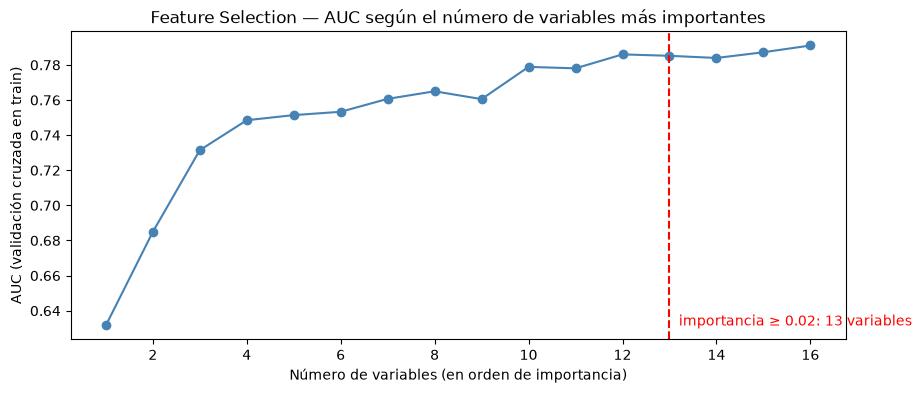

Variables seleccionadas (13): ['altura_prom', 'limpio_vs_esperado', 'pct_internacional', 'altura_max', 'altura_max_limpio', 'pct_limpios', 'pct_limpio_130', 'altura_std', 'n_recorridos', 'edad_inicio', 'n_limpios', 'nationalFederation_bel', 'pct_exterior_fei']
Descartadas: ['gender_female', 'nationalFederation_swe', 'gender_desconocido']
Las dos mejores variables: ['altura_prom', 'limpio_vs_esperado']


,n_variables,AUC (CV),variable agregada
0,1,0.632,altura_prom
1,2,0.685,limpio_vs_esperado
2,3,0.731,pct_internacional
3,4,0.749,altura_max
4,5,0.751,altura_max_limpio
5,6,0.753,pct_limpios
6,7,0.761,pct_limpio_130
7,8,0.765,altura_std
8,9,0.761,n_recorridos
9,10,0.779,edad_inicio


In [36]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
orden = importancias.index.tolist()
auc_por_n = []
for n in range(1, len(orden) + 1):
    rf_n = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced', random_state=SEED, n_jobs=-1)
    auc_por_n.append(cross_val_score(rf_n, X_train_enc[orden[:n]], y_train, cv=cv5, scoring='roc_auc').mean())

curva_fs = pd.DataFrame({'n_variables': range(1, len(orden) + 1), 'AUC (CV)': auc_por_n, 'variable agregada': orden})
seleccionadas = importancias[importancias >= 0.02].index.tolist()
n_sel = len(seleccionadas)
top2 = orden[:2]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(curva_fs['n_variables'], curva_fs['AUC (CV)'], marker='o', color='steelblue')
ax.axvline(n_sel, color='red', ls='--'); ax.text(n_sel + .2, curva_fs['AUC (CV)'].min(), f'importancia ≥ 0.02: {n_sel} variables', color='red')
ax.set_xlabel('Número de variables (en orden de importancia)'); ax.set_ylabel('AUC (validación cruzada en train)')
ax.set_title('Feature Selection — AUC según el número de variables más importantes')
plt.show()

print(f"Variables seleccionadas ({n_sel}): {seleccionadas}")
print(f"Descartadas: {[c for c in orden if c not in seleccionadas]}")
print(f"Las dos mejores variables: {top2}")
curva_fs.round(3)

**Interpretación**
- Las dos variables más importantes son la **altura promedio** (dificultad) y **limpio vs esperado** (consistencia: sale limpio más seguido de lo normal para las alturas que salta). Les siguen el **% internacional** (circuito), la altura máxima y la altura máxima en limpio.
- Se descartan **3 variables**: el **sexo** (`gender_female`, `gender_desconocido`) y ser de **Suecia**. Una vez que se conoce el historial deportivo, casi no aportan.
- La curva sube rápido con las primeras 3 o 4 variables y después crece poco. Agregar las 3 descartadas no cambia el AUC de forma relevante, lo que confirma la selección.

---
# Parte 4. Modelos de analítica predictiva

Se comparan los modelos vistos en clase sobre los mismos datos y la misma partición. Todas las métricas se guardan en `comparacion`.

## 4.0 ¿Contra qué comparamos? Dos modelos ingenuos
1. **"Ninguno llega":** predecir siempre 0.
2. **"La regla del entrenador":** *llegará si a los 8 años ya intentó una prueba de al menos O cm*. El umbral O se elige **con train** (el que da mejor F1).

In [37]:
from sklearn.metrics import f1_score

comparacion = []

pred_ninguno = np.zeros(len(y_test), dtype=int)
comparacion.append(evaluar_completo('Ninguno llega', y_test, pred_ninguno, np.zeros(len(y_test))))

umbrales_altura = range(120, 161)
O = max(umbrales_altura, key=lambda o: f1_score(y_train, (X_train_enc['altura_max'] >= o).astype(int)))
pred_regla = (X_test_enc['altura_max'] >= O).astype(int)
comparacion.append(evaluar_completo(f'Regla: altura máx ≥ {O} cm', y_test, pred_regla, X_test_enc['altura_max']))

Ninguno llega: exactitud 0.733 | precisión 0.0 | recall 0.0 | F1 0.0
               exactitud balanceada 0.5 | AUC 0.5
Regla: altura máx ≥ 136 cm: exactitud 0.573 | precisión 0.365 | recall 0.806 | F1 0.503
                            exactitud balanceada 0.647 | AUC 0.75


"Ninguno llega" tiene una exactitud alta sin aprender nada, pero su **recall es 0**: no encuentra a ningún futuro campeón. La regla del entrenador sí detecta a varios, y es la que hay que superar.

## 4.1 Versión 1: modelos con las 2 mejores variables (región de clasificación)
Se entrenan los cuatro modelos solo con las **dos variables más importantes** para poder **dibujar su región de clasificación**. Se usan los datos escalados para que los ejes sean comparables.

Regresión logística (2 var.): exactitud 0.685 | precisión 0.449 | recall 0.774 | F1 0.568
                              exactitud balanceada 0.714 | AUC 0.789
KNN (k=25) (2 var.): exactitud 0.784 | precisión 0.75 | recall 0.29 | F1 0.419
                     exactitud balanceada 0.628 | AUC 0.752
Árbol de decisión (2 var.): exactitud 0.625 | precisión 0.391 | recall 0.726 | F1 0.508
                            exactitud balanceada 0.657 | AUC 0.717
Random Forest (2 var.): exactitud 0.634 | precisión 0.393 | recall 0.677 | F1 0.497
                        exactitud balanceada 0.648 | AUC 0.749


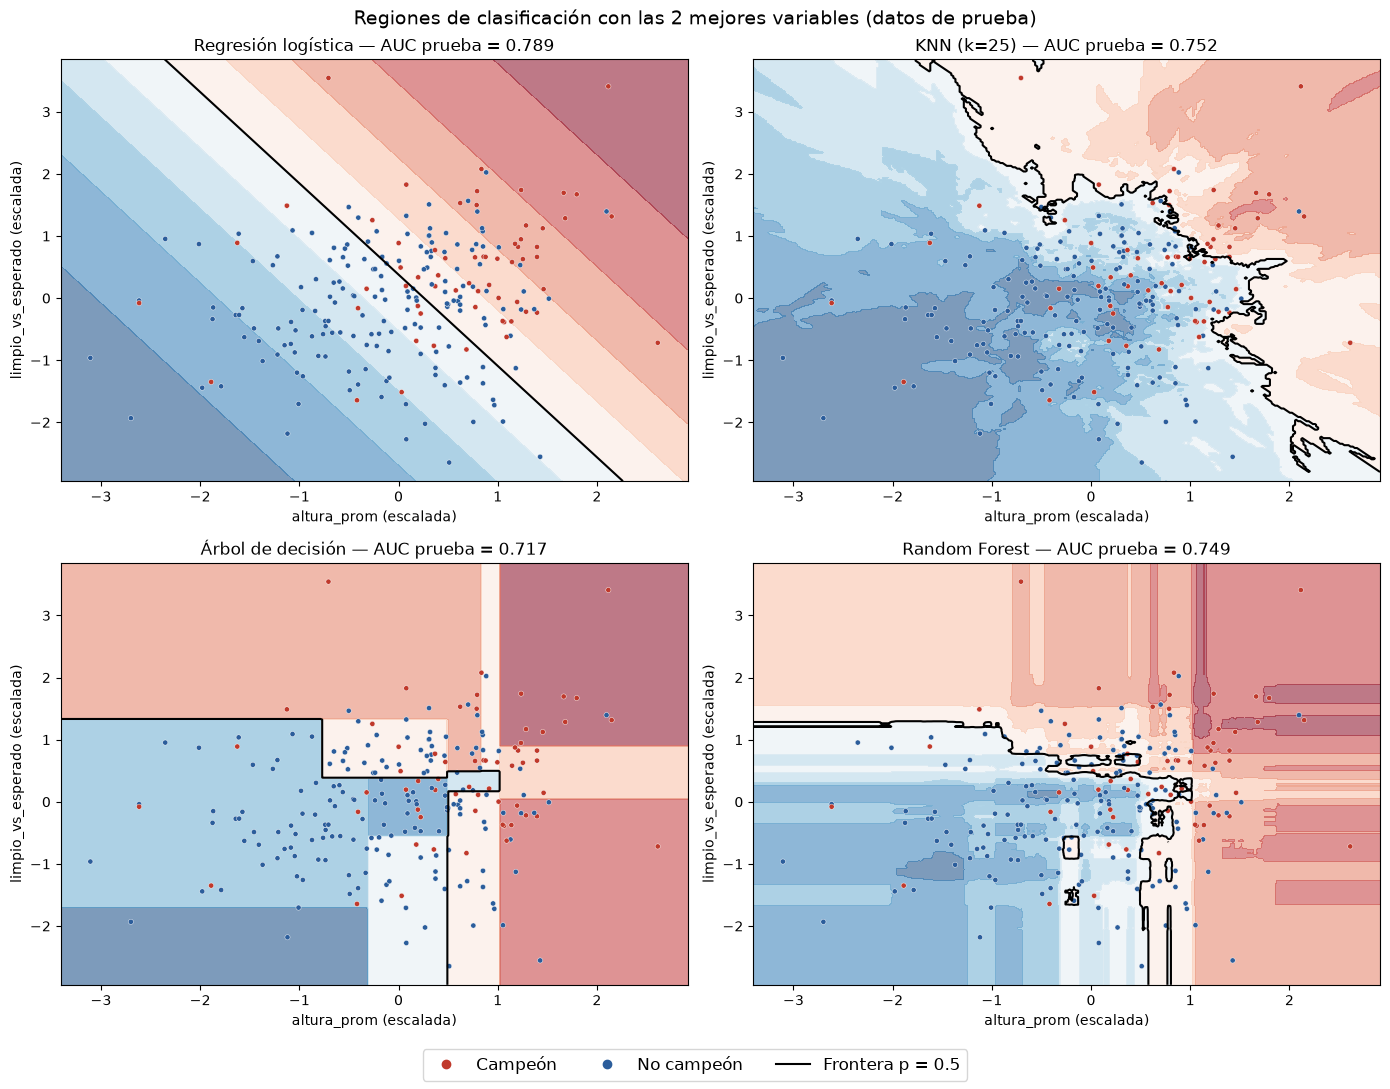

In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

modelos_2v = {
    'Regresión logística': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'KNN (k=25)': KNeighborsClassifier(n_neighbors=25),
    'Árbol de decisión': DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, class_weight='balanced', random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=15, class_weight='balanced', random_state=SEED, n_jobs=-1),
}

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (nombre, modelo) in zip(axes.flat, modelos_2v.items()):
    modelo.fit(X_train_escalado[top2], y_train)
    proba = modelo.predict_proba(X_test_escalado[top2])[:, 1]
    m = evaluar_completo(f'{nombre} (2 var.)', y_test, (proba >= 0.5).astype(int), proba)
    comparacion.append(m)
    plot_region(modelo, X_test_escalado[top2], y_test, top2, f"{nombre} — AUC prueba = {m['AUC']:.3f}", ax=ax)
fig.legend(handles=[Line2D([], [], marker='o', ls='', color='#c0392b', label='Campeón'),
                    Line2D([], [], marker='o', ls='', color='#2b5d9b', label='No campeón'),
                    Line2D([], [], color='k', label='Frontera p = 0.5')], loc='lower center', ncol=3, fontsize=12)
plt.suptitle('Regiones de clasificación con las 2 mejores variables (datos de prueba)', fontsize=14)
plt.tight_layout(rect=[0, .04, 1, 1])
plt.show()

In [39]:
# % de campeones por zona: altura promedio (cuartiles) × consistencia (terciles)
zonas = X_train_enc[['altura_prom', 'limpio_vs_esperado']].assign(campeon=y_train.values)
zonas['Altura promedio'] = pd.qcut(zonas['altura_prom'], 4, labels=['Baja', 'Media-baja', 'Media-alta', 'Alta'])
zonas['Consistencia'] = pd.qcut(zonas['limpio_vs_esperado'], 3,
                                labels=['Peor que lo esperado', 'Normal', 'Mejor que lo esperado'])

tasa_zona = zonas.pivot_table(index='Consistencia', columns='Altura promedio', values='campeon',
                              aggfunc='mean', observed=False).iloc[::-1]

fig = px.imshow(tasa_zona * 100, text_auto='.0f', color_continuous_scale='RdBu_r', zmin=0, zmax=60,
                labels={'color': '% campeones'}, aspect='auto',
                title='% de caballos que llegaron a la élite según su perfil a los 8 años (train)')
fig.update_layout(width=850, height=450)
fig.show()

**Lee las regiones** *(el color es la probabilidad de llegar a la élite: rojo = alta)*
- Los futuros campeones (puntos rojos) se concentran **arriba a la derecha**: caballos que a los 8 años ya compiten **más alto en promedio** y que además **salen limpios más seguido de lo esperado** para esas alturas. Abajo a la izquierda casi no hay campeones.
- Ninguna de las dos variables separa sola a los grupos: hay campeones con altura promedio media pero muy consistentes, y caballos que compiten alto pero con muchos derribos que no llegan. **Se necesitan las dos juntas.**
- Con dos variables, la **regresión logística** es la que mejor ordena (AUC 0.79): la relación es casi lineal.
- La **regresión logística** traza una frontera **recta**; el **árbol**, **escalones** rectangulares; **KNN**, una frontera irregular que sigue a los vecinos; el **Random Forest**, escalones más suaves porque promedia muchos árboles.
- Con solo dos variables los modelos quedan cerca entre sí. Hacen falta más variables para mejorar, lo que justifica la versión 2.

## 4.2 Regresión logística (statsmodels)
Se ajusta con `statsmodels` para tener el resumen estadístico y leer los coeficientes como **razón de momios**. Se usan las variables seleccionadas, **sin escalar**, para interpretarlas en sus unidades.

In [40]:
modelo_logit = ajustar_logit(X_train_enc[seleccionadas], y_train)
print(modelo_logit.summary())

                           Logit Regression Results                           
Dep. Variable:               champion   No. Observations:                  927
Model:                          Logit   Df Residuals:                      913
Method:                           MLE   Df Model:                           13
Date:                Mon, 09 Nov 2026   Pseudo R-squ.:                  0.2225
Time:                        01:37:20   Log-Likelihood:                -419.36
converged:                       True   LL-Null:                       -539.39
Covariance Type:            nonrobust   LLR p-value:                 7.346e-44
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     13.4578      9.857      1.365      0.172      -5.861      32.776
altura_prom               -0.0899      0.049     -1.843      0.065      -0.186       0.006
limp

In [41]:
razon_de_momios(modelo_logit)

,coef (log-odds),razón de momios,p-value
const,13.4578,6.992870e+05,0.1721
altura_prom,-0.0899,9.140000e-01,0.0653
limpio_vs_esperado,29.1025,4.355544e+12,0.0029
pct_internacional,0.7529,2.123000e+00,0.0498
altura_max,0.0837,1.087000e+00,0.0049
altura_max_limpio,0.0015,1.001000e+00,0.8857
pct_limpios,-28.2686,0.000000e+00,0.0041
pct_limpio_130,0.4348,1.545000e+00,0.5101
altura_std,-0.0407,9.600000e-01,0.4499
n_recorridos,-0.0316,9.690000e-01,0.0238


In [42]:
X_train_enc[seleccionadas].corr().round(2)

,altura_prom,limpio_vs_esperado,pct_internacional,altura_max,altura_max_limpio,pct_limpios,pct_limpio_130,altura_std,n_recorridos,edad_inicio,n_limpios,nationalFederation_bel,pct_exterior_fei
altura_prom,1.00,0.23,0.48,0.81,0.49,0.04,0.48,-0.18,-0.05,0.31,-0.01,-0.02,0.36
limpio_vs_esperado,0.23,1.00,0.11,0.27,0.42,0.98,0.63,0.12,0.06,-0.09,0.41,0.06,0.16
pct_internacional,0.48,0.11,1.00,0.39,0.22,-0.00,0.17,-0.06,-0.08,0.10,-0.05,0.22,0.48
altura_max,0.81,0.27,0.39,1.00,0.60,0.12,0.52,0.29,0.17,-0.02,0.21,0.09,0.46
altura_max_limpio,0.49,0.42,0.22,0.60,1.00,0.34,0.48,0.18,0.23,-0.08,0.28,0.03,0.27
pct_limpios,0.04,0.98,-0.00,0.12,0.34,1.00,0.56,0.15,0.08,-0.16,0.44,0.06,0.08
pct_limpio_130,0.48,0.63,0.17,0.52,0.48,0.56,1.00,0.12,0.15,-0.03,0.36,-0.02,0.26
altura_std,-0.18,0.12,-0.06,0.29,0.18,0.15,0.12,1.00,0.20,-0.50,0.23,0.26,0.13
n_recorridos,-0.05,0.06,-0.08,0.17,0.23,0.08,0.15,0.20,1.00,-0.48,0.89,-0.23,0.25
edad_inicio,0.31,-0.09,0.10,-0.02,-0.08,-0.16,-0.03,-0.50,-0.48,1.00,-0.48,-0.26,-0.16


**interpretación** *(revisa p-values y correlaciones)*
- En el modelo completo varios coeficientes no son significativos y algunos salen con signos raros. Es el síntoma de la redundancia entre variables, que se corrige abajo.
- Varias variables están **muy correlacionadas** entre sí porque miden casi lo mismo (por ejemplo, `pct_limpios` y `limpio_vs_esperado`, o `altura_prom` y `altura_max`). Igual que con `fare` y `pclass` en el Titanic, cuando dos variables se traslapan los coeficientes se vuelven inestables: pueden salir enormes y con signos opuestos. Por eso, antes de leer momios:
  1. De cada par con correlación mayor a 0.75 se quita la variable **menos importante** según el Random Forest.
  2. Después se **depura por p-values**, quitando una por una las que tengan p > 0.05.

In [43]:
# 1. Quitar redundancias (|correlación| > 0.75): se queda la variable más importante del par
corr = X_train_enc[seleccionadas].corr().abs()
columnas_logit = list(seleccionadas)            # ya vienen ordenadas de más a menos importante
for i, a in enumerate(seleccionadas):
    for b in seleccionadas[i + 1:]:
        if a in columnas_logit and b in columnas_logit and corr.loc[a, b] > 0.75:
            print(f"{a} y {b} tienen correlación {corr.loc[a, b]:.2f} → se quita {b}")
            columnas_logit.remove(b)

# 2. Depurar por p-values: se eliminan una por una las variables con p-value > 0.05
while True:
    modelo_logit = ajustar_logit(X_train_enc[columnas_logit], y_train)
    pvals = modelo_logit.pvalues.drop('const')
    if pvals.max() <= 0.05:
        break
    print(f"Se elimina {pvals.idxmax()} (p = {pvals.max():.3f})")
    columnas_logit.remove(pvals.idxmax())

print(f"\nVariables finales de la logística: {columnas_logit}")
momios = razon_de_momios(modelo_logit)
# Las proporciones van de 0 a 1: es más fácil leer el efecto de +0.10 (10 puntos porcentuales)
proporciones = [c for c in columnas_logit if c.startswith('pct_') or c == 'limpio_vs_esperado']
momios['momios por +10 puntos %'] = [round(np.exp(0.1 * b), 3) if c in proporciones else np.nan
                                     for c, b in modelo_logit.params.items()]
momios

altura_prom y altura_max tienen correlación 0.81 → se quita altura_max
limpio_vs_esperado y pct_limpios tienen correlación 0.98 → se quita pct_limpios
n_recorridos y n_limpios tienen correlación 0.89 → se quita n_limpios
Se elimina pct_limpio_130 (p = 0.871)
Se elimina altura_max_limpio (p = 0.630)
Se elimina pct_exterior_fei (p = 0.113)

Variables finales de la logística: ['altura_prom', 'limpio_vs_esperado', 'pct_internacional', 'altura_std', 'n_recorridos', 'edad_inicio', 'nationalFederation_bel']


,coef (log-odds),razón de momios,p-value,momios por +10 puntos %
const,-13.8093,0.000,0.0000,NaN
altura_prom,0.1140,1.121,0.0000,NaN
limpio_vs_esperado,2.5736,13.113,0.0000,1.294
pct_internacional,1.0710,2.918,0.0014,1.113
altura_std,0.1060,1.112,0.0067,NaN
n_recorridos,-0.0103,0.990,0.0112,NaN
edad_inicio,-0.4170,0.659,0.0011,NaN
nationalFederation_bel,0.6150,1.850,0.0029,NaN


### El umbral de decisión
Con 27% de campeones, el umbral 0.5 deja ir a muchos. Igual que en el Titanic, se prueban varios umbrales, pero se elige **con train** (el que maximiza F1) para no hacer trampa con el conjunto de prueba.

In [44]:
proba_logit_train = predecir_proba(modelo_logit, X_train_enc[columnas_logit])
proba_logit = predecir_proba(modelo_logit, X_test_enc[columnas_logit])

umbrales = np.arange(0.10, 0.71, 0.05)
umbral_logit = max(umbrales, key=lambda u: f1_score(y_train, (proba_logit_train >= u).astype(int)))
print(f"Umbral elegido con train: {umbral_logit:.2f}")

comparacion.append(evaluar_completo('Logística (umbral 0.5)', y_test, (proba_logit >= 0.5).astype(int), proba_logit))
comparacion.append(evaluar_completo(f'Logística (umbral {umbral_logit:.2f})', y_test, (proba_logit >= umbral_logit).astype(int), proba_logit))
plot_metricas_por_umbral(y_test, proba_logit)

Umbral elegido con train: 0.35
Logística (umbral 0.5): exactitud 0.806 | precisión 0.689 | recall 0.5 | F1 0.579
                        exactitud balanceada 0.709 | AUC 0.821
Logística (umbral 0.35): exactitud 0.78 | precisión 0.568 | recall 0.742 | F1 0.643
                         exactitud balanceada 0.768 | AUC 0.821


**Interpretación de los momios del modelo depurado** *(manteniendo todo lo demás igual)*
- **Altura promedio:** cada cm adicional multiplica los momios de llegar a la élite por **1.12** (+12%). Competir 10 cm más alto en promedio los multiplica por ≈ 3.1.
- **Limpio vs esperado:** salir limpio 10 puntos porcentuales más seguido de lo esperado multiplica los momios por **1.29** (+29%).
- **% internacional:** 10 puntos porcentuales más de pruebas FEI multiplican los momios por **1.11** (+11%).
- **Edad de inicio:** cada año que el caballo tarda en empezar a competir multiplica los momios por **0.66** (−34%). Coincide con el estudio original: los futuros campeones empiezan antes.
- **Número de recorridos:** cada recorrido extra multiplica los momios por **0.99**. Con la misma altura y consistencia, competir mucho sin subir de nivel es mala señal.
- **Bélgica:** un caballo belga tiene momios **1.85** veces los de un francés con el mismo historial.
- **Variabilidad de altura:** cada cm de desviación multiplica los momios por **1.11**: los futuros campeones prueban un rango más amplio de alturas.

**El umbral.** Con 0.5 la logística solo encuentra a la mitad de los campeones (recall 0.50). Con el umbral elegido en train (0.35) el recall sube a **0.74** y el F1 a 0.64, a cambio de más falsas alarmas. La probabilidad permite elegir qué error preferimos, algo que la regla del entrenador no puede hacer.

## 4.3 KNN
Se usan los datos **escalados**. El k se elige con validación cruzada dentro de train, como en la sesión de KNN, pero con **exactitud balanceada** en vez de exactitud: con 27% de campeones, la exactitud premia a un k enorme que casi siempre vota "no llega".

In [45]:
valores_k = range(1, 61, 2)
bal_cv = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_escalado[seleccionadas], y_train,
                          cv=cv5, scoring='balanced_accuracy').mean() for k in valores_k]
mejor_k = plot_curva_k(valores_k, bal_cv, metrica='Exactitud balanceada', menor_es_mejor=False)
print(f"Mejor k: {mejor_k}")

Mejor k: 7


In [46]:
knn = KNeighborsClassifier(n_neighbors=mejor_k).fit(X_train_escalado[seleccionadas], y_train)
proba_knn_train = knn.predict_proba(X_train_escalado[seleccionadas])[:, 1]
proba_knn = knn.predict_proba(X_test_escalado[seleccionadas])[:, 1]
umbral_knn = max(umbrales, key=lambda u: f1_score(y_train, (proba_knn_train >= u).astype(int)))

comparacion.append(evaluar_completo(f'KNN (k={mejor_k}, umbral 0.5)', y_test, (proba_knn >= 0.5).astype(int), proba_knn))
comparacion.append(evaluar_completo(f'KNN (k={mejor_k}, umbral {umbral_knn:.2f})', y_test, (proba_knn >= umbral_knn).astype(int), proba_knn))

KNN (k=7, umbral 0.5): exactitud 0.759 | precisión 0.562 | recall 0.435 | F1 0.491
                       exactitud balanceada 0.656 | AUC 0.774
KNN (k=7, umbral 0.30): exactitud 0.737 | precisión 0.507 | recall 0.597 | F1 0.548
                        exactitud balanceada 0.693 | AUC 0.774


KNN eligió **k = 7**. Con el umbral 0.5 su recall es bajo (0.44): como los campeones son el 27%, rara vez son mayoría entre los vecinos. Moviendo el umbral mejora, pero queda por debajo de la logística y del Random Forest (AUC 0.77). Igual que en el Titanic, KNN le da el mismo peso a todas las variables y no sabe que la altura y la consistencia importan más que el número de recorridos. Además, no da coeficientes que interpretar.

## 4.4 Árbol de decisión
### Primero, el error clásico: sin podar

In [47]:
arbol_sin_podar = DecisionTreeClassifier(class_weight='balanced', random_state=SEED).fit(X_train_enc[seleccionadas], y_train)
print(f"Sin podar — AUC train: {roc_auc_score(y_train, arbol_sin_podar.predict_proba(X_train_enc[seleccionadas])[:, 1]):.3f} | "
      f"AUC prueba: {roc_auc_score(y_test, arbol_sin_podar.predict_proba(X_test_enc[seleccionadas])[:, 1]):.3f} | "
      f"hojas: {arbol_sin_podar.get_n_leaves()}")

Sin podar — AUC train: 1.000 | AUC prueba: 0.662 | hojas: 171


### Podar con validación cruzada

In [48]:
from sklearn.model_selection import GridSearchCV

busqueda_arbol = GridSearchCV(
    DecisionTreeClassifier(class_weight='balanced', random_state=SEED),
    {'max_depth': [2, 3, 4, 5, 6, 8, 10, None], 'min_samples_leaf': [1, 5, 10, 20, 40]},
    cv=cv5, scoring='roc_auc', n_jobs=-1)
busqueda_arbol.fit(X_train_enc[seleccionadas], y_train)
arbol = busqueda_arbol.best_estimator_

print(f"Mejores parámetros: {busqueda_arbol.best_params_}")
print(f"AUC de validación cruzada: {busqueda_arbol.best_score_:.3f}")
print(f"Podado — AUC train: {roc_auc_score(y_train, arbol.predict_proba(X_train_enc[seleccionadas])[:, 1]):.3f} | hojas: {arbol.get_n_leaves()}")

proba_arbol = arbol.predict_proba(X_test_enc[seleccionadas])[:, 1]
comparacion.append(evaluar_completo('Árbol podado', y_test, (proba_arbol >= 0.5).astype(int), proba_arbol))

Mejores parámetros: {'max_depth': 6, 'min_samples_leaf': 40}
AUC de validación cruzada: 0.759
Podado — AUC train: 0.829 | hojas: 16
Árbol podado: exactitud 0.681 | precisión 0.439 | recall 0.694 | F1 0.537
              exactitud balanceada 0.685 | AUC 0.767


In [49]:
profundidades = [1, 2, 3, 4, 5, 6, 8, 10, 15]
auc_train, auc_test = [], []
for d in profundidades:
    m = DecisionTreeClassifier(max_depth=d, class_weight='balanced', random_state=SEED).fit(X_train_enc[seleccionadas], y_train)
    auc_train.append(roc_auc_score(y_train, m.predict_proba(X_train_enc[seleccionadas])[:, 1]))
    auc_test.append(roc_auc_score(y_test, m.predict_proba(X_test_enc[seleccionadas])[:, 1]))
plot_curva_complejidad(profundidades, auc_train, auc_test, parametro='max_depth', metrica='AUC')

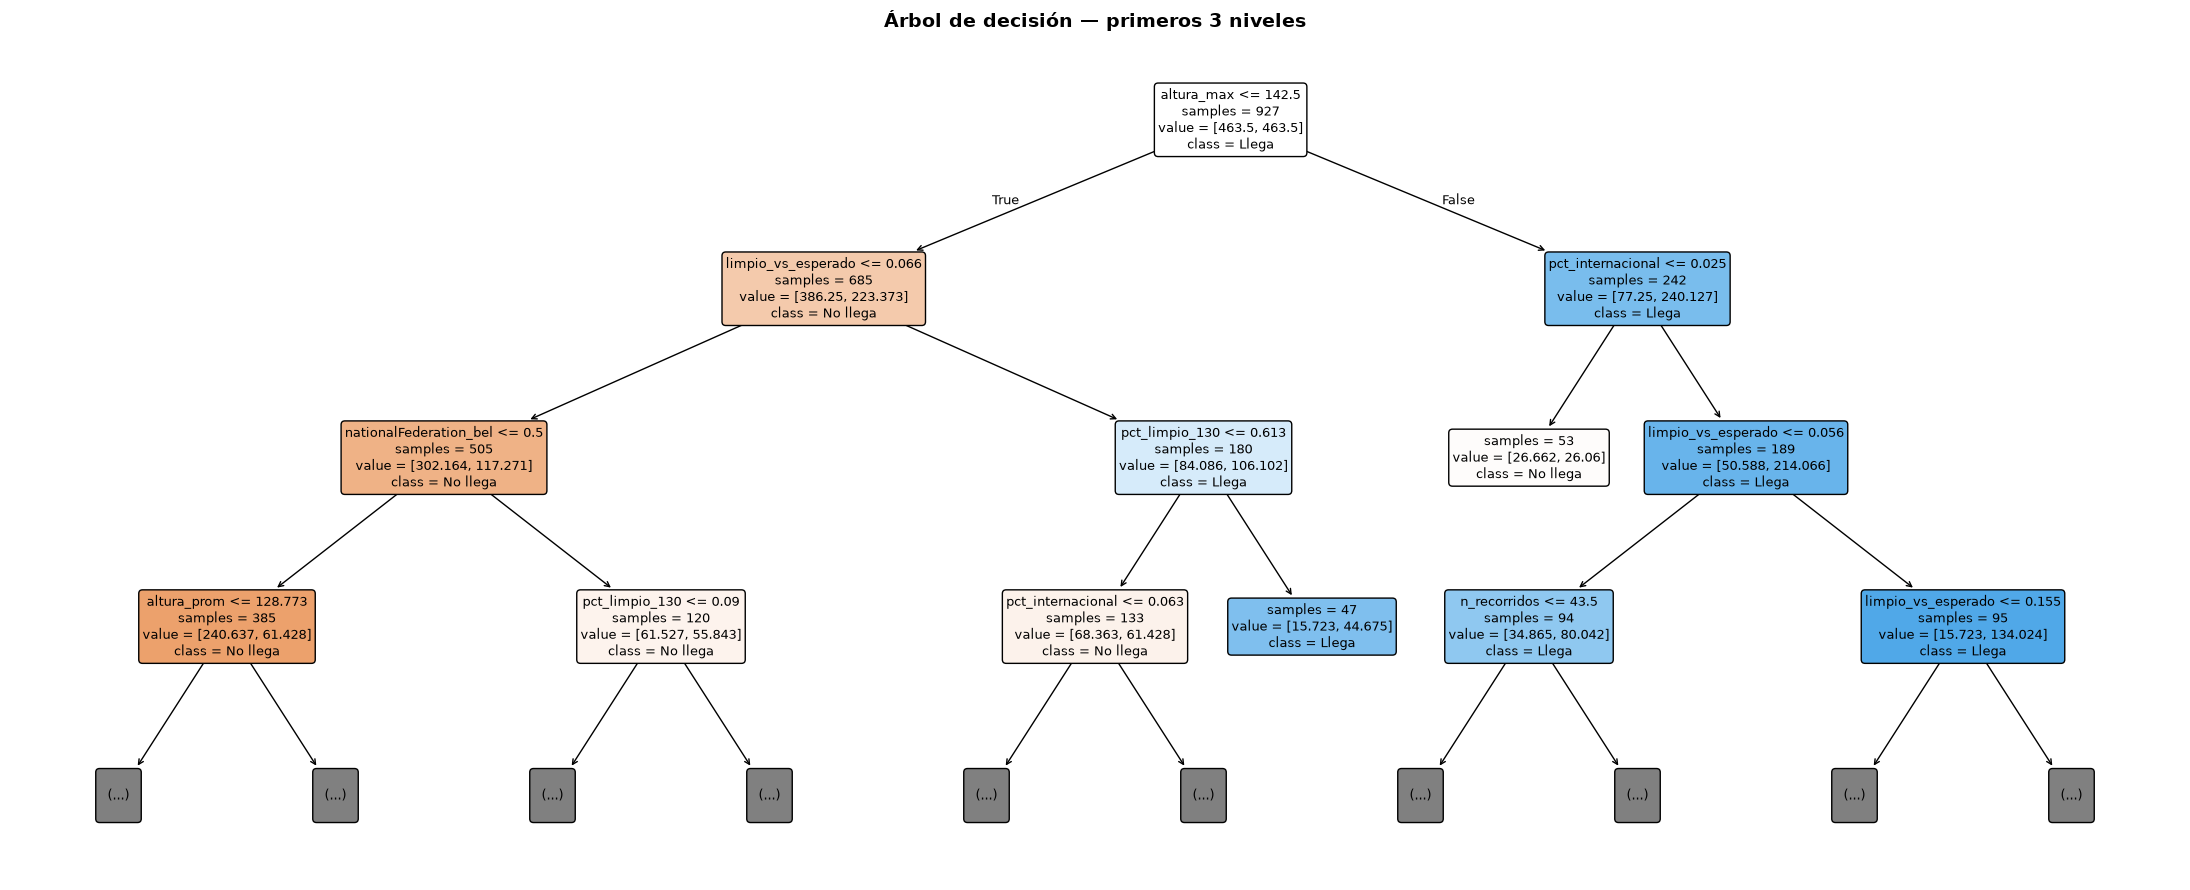

In [50]:
plot_arbol(arbol, seleccionadas, max_depth=3, class_names=['No llega', 'Llega'])

**Lectura del árbol** *(naranja = no llega, azul = llega)*
- **Primera pregunta: ¿su altura máxima es mayor a 142.5 cm?** Es la versión del árbol de la "regla del entrenador".
- Si **no** ha pasado de 142.5 cm, el árbol pregunta por la **consistencia** (`limpio_vs_esperado`): los que salen limpios más seguido de lo esperado todavía tienen buena probabilidad.
- Si **sí** pasó de 142.5 cm, la siguiente pregunta es si ha competido en **pruebas internacionales**. Los que compiten alto pero sin nada de circuito FEI se parecen más a los que no llegan.

**Sobreajuste.** Sin podar, el árbol tiene 171 hojas y un AUC de 1.0 en train, pero de 0.66 en prueba: memorizó los datos. Podado (`max_depth=6`, `min_samples_leaf=40`) queda con 16 hojas y sube a 0.77 en prueba. La curva de complejidad muestra cómo se separan train y prueba al crecer la profundidad.

## 4.5 🏆 Modelo definitivo: Random Forest

### ¿Qué es?
Un Random Forest es un **conjunto de muchos árboles de decisión que votan**. Es la extensión directa del árbol que vimos en clase:
1. Cada árbol se entrena con una **muestra bootstrap** de los caballos (con reemplazo), lo que se conoce como *bagging*.
2. En cada división, cada árbol solo puede elegir entre un **subconjunto aleatorio de variables** (`max_features`). Así los árboles salen distintos entre sí.
3. Cada árbol divide buscando la menor **impureza de Gini**: $G = 1 - \sum_k p_k^2$.
4. La probabilidad final es el **promedio** de las probabilidades de todos los árboles.

### ¿Por qué funciona mejor que un árbol?
Un árbol solo tiene **alta varianza**: cambia mucho si cambian un poco los datos, y tiende a memorizar (lo vimos sin podar). Al promediar cientos de árboles **poco correlacionados**, los errores de cada uno se compensan y la varianza baja sin subir el sesgo. Además:
- Captura relaciones **no lineales** e **interacciones** (por ejemplo, "compite alto **y** sale limpio") sin tener que especificarlas.
- No necesita escalamiento y es robusto a outliers.
- Da una **importancia de variables** más estable que un solo árbol.

### Hiperparámetros (GridSearchCV con 5 pliegues dentro de train, optimizando AUC)
| Hiperparámetro | Qué controla |
|---|---|
| `n_estimators` | Número de árboles |
| `max_depth`, `min_samples_leaf` | Qué tan complejo es cada árbol (la "poda") |
| `max_features` | Cuántas variables puede probar cada división |
| `class_weight` | *balanced* hace que cada campeón "pese" más, compensando que son solo el 27% |

In [ ]:
busqueda_rf = GridSearchCV(
    RandomForestClassifier(random_state=SEED, n_jobs=-1),
    {'n_estimators': [300, 600], 'max_depth': [4, 8, 12, None], 'min_samples_leaf': [5, 10, 20],
     'max_features': ['sqrt', 0.5], 'class_weight': ['balanced', 'balanced_subsample']},
    cv=cv5, scoring='roc_auc', n_jobs=-1)
busqueda_rf.fit(X_train_enc[seleccionadas], y_train)
rf = busqueda_rf.best_estimator_

print(f"Mejores parámetros: {busqueda_rf.best_params_}")
print(f"AUC de validación cruzada (train): {busqueda_rf.best_score_:.3f}")

In [ ]:
proba_rf_train = rf.predict_proba(X_train_enc[seleccionadas])[:, 1]
proba_rf = rf.predict_proba(X_test_enc[seleccionadas])[:, 1]
pred_rf = (proba_rf >= 0.5).astype(int)
print(f"AUC train: {roc_auc_score(y_train, proba_rf_train):.3f} | AUC prueba: {roc_auc_score(y_test, proba_rf):.3f}")
comparacion.append(evaluar_completo('Random Forest (umbral 0.5)', y_test, pred_rf, proba_rf))

In [ ]:
plot_matriz_confusion(y_test, pred_rf, etiquetas=('No llega', 'Llega'), title='Matriz de confusión — Random Forest')

In [ ]:
plot_curva_roc(y_test, proba_rf, title='Curva ROC — Random Forest')

In [ ]:
plot_metricas_por_umbral(y_test, proba_rf)

In [ ]:
importancias_rf = plot_importancias(rf, seleccionadas)
importancias_rf

**Lectura de la matriz de confusión** *(232 caballos de prueba, 62 campeones)*
- El Random Forest detectó a **43 de los 62** futuros campeones (recall **0.69**) y se le escaparon 19.
- Marcó como "llega" a 83 caballos, de los cuales 43 sí llegaron (precisión **0.52**). Es casi el doble del 27% de partida: si el criadero invierte en los caballos que marca el modelo, la mitad llegará a la élite, contra uno de cada cuatro sin modelo.
- AUC de **0.81** en prueba y **0.85** en train: la distancia es moderada, así que el modelo no está memorizando. La "poda" del bosque (`max_depth=4`, `min_samples_leaf=20`) controla el sobreajuste.
- En importancia, el bosque reparte el peso entre **altura máxima, % internacional, altura promedio, altura máxima en limpio y limpio vs esperado**, sin que una sola variable domine.

## 4.6 Complemento no supervisado: clustering (K-means)
¿Hay **perfiles naturales** de caballos jóvenes, sin decirle al algoritmo quién llegó a la élite? Se usa K-means sobre las variables seleccionadas **escaladas** (mide distancias), y después se compara la tasa de campeones de cada grupo.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

valores_c = range(2, 9)
inercia, silueta = [], []
for c in valores_c:
    km = KMeans(n_clusters=c, n_init=10, random_state=SEED).fit(X_train_escalado[seleccionadas])
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(X_train_escalado[seleccionadas], km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(valores_c), inercia, marker='o'); axes[0].set_title('Método del codo'); axes[0].set_xlabel('k'); axes[0].set_ylabel('Inercia')
axes[1].plot(list(valores_c), silueta, marker='o', color='tomato'); axes[1].set_title('Coeficiente de silueta'); axes[1].set_xlabel('k')
plt.tight_layout(); plt.show()
pd.DataFrame({'k': list(valores_c), 'inercia': inercia, 'silueta': silueta}).round(3)

In [ ]:
K = 3   # la silueta es baja para todos los k (no hay grupos muy marcados); se elige 3 por ser interpretable
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X_train_escalado[seleccionadas])
perfil = X_train_enc[seleccionadas].assign(grupo=kmeans.labels_, campeon=y_train.values)
resumen_grupos = perfil.groupby('grupo').mean().round(3)
resumen_grupos.insert(0, 'caballos', perfil['grupo'].value_counts().sort_index())
resumen_grupos.rename(columns={'campeon': 'tasa de campeones'})

In [ ]:
# Región de agrupación con las 2 mejores variables
km2 = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X_train_escalado[top2])
x1, x2 = top2
xx, yy = np.meshgrid(np.linspace(X_train_escalado[x1].min() - .3, X_train_escalado[x1].max() + .3, 300),
                     np.linspace(X_train_escalado[x2].min() - .3, X_train_escalado[x2].max() + .3, 300))
Z = km2.predict(pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=top2)).reshape(xx.shape)
tasas = pd.Series(y_train.values).groupby(km2.labels_).mean()

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.contourf(xx, yy, Z, levels=np.arange(K + 1) - .5, cmap='Pastel1', alpha=.8)
ax.scatter(X_train_escalado[x1], X_train_escalado[x2], c=np.where(y_train == 1, '#c0392b', '#2b5d9b'), s=12, edgecolor='white', linewidth=.3)
for i, (cx, cy) in enumerate(km2.cluster_centers_):
    ax.scatter(cx, cy, marker='X', s=250, c='k')
    ax.annotate(f'Grupo {i}\n{tasas[i]:.0%} campeones', (cx, cy), xytext=(8, 8), textcoords='offset points', fontsize=11, weight='bold')
ax.set_xlabel(f'{x1} (escalada)'); ax.set_ylabel(f'{x2} (escalada)')
ax.set_title(f'K-means (k={K}) con las 2 mejores variables — regiones de agrupación (train)')
ax.legend(handles=[Line2D([], [], marker='o', ls='', color='#c0392b', label='Campeón'),
                   Line2D([], [], marker='o', ls='', color='#2b5d9b', label='No campeón'),
                   Line2D([], [], marker='X', ls='', color='k', label='Centroide')], loc='upper left')
plt.show()

**Observaciones**
- El **coeficiente de silueta es bajo para cualquier k** (menos de 0.2): los caballos no forman grupos muy separados, sino un continuo. Se eligió **k = 3** porque da perfiles fáciles de interpretar.
- Aun así, sin conocer el target, K-means separa perfiles con tasas de campeones muy distintas:
  - **Caballos de circuito nacional bajo:** altura promedio ≈ 120 cm, casi sin pruebas internacionales y peor que lo esperado en limpios → **≈ 11% campeones**.
  - **Caballos que compiten mucho a nivel medio:** ≈ 126 cm, muchos recorridos y buena consistencia → **≈ 32% campeones**.
  - **Caballos de circuito internacional alto:** ≈ 131 cm y la mayor proporción de pruebas FEI → **≈ 40% campeones**.
- Con las 2 mejores variables pasa lo mismo: el grupo de **altura alta y buena consistencia** concentra la mayor tasa de campeones (≈ 42%), contra ≈ 11% del grupo de altura baja.
- Conclusión: el clustering **confirma** lo que encontró el modelo supervisado, pero los grupos se traslapan mucho, así que **no sustituye** a la clasificación.

## 4.7 Comparación de todos los modelos (partición 80/20)

In [ ]:
pd.DataFrame(comparacion).sort_values('AUC', ascending=False)

---
# Parte 5. Evaluación: validación cruzada de 10 pliegues

Una sola partición 80/20 puede salir "con suerte". Se repite la evaluación con **10 pliegues estratificados** sobre todos los caballos: en cada pliegue el modelo se entrena con el 90% y se evalúa en el **10% que no vio (datos de prueba del pliegue)**.

Para que no haya fuga, **todo el preprocesamiento que aprende de los datos va dentro de un `Pipeline`**: el recorte de outliers (`RecortadorIQR`) y el escalamiento se vuelven a ajustar en cada pliegue solo con su parte de entrenamiento.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Base completa con nulos imputados (valores fijos, sin fuga) y categóricas codificadas
X_full = X.copy()
X_full['altura_max_limpio'] = X_full['altura_max_limpio'].fillna(0)
X_full['pct_limpio_130'] = X_full['pct_limpio_130'].fillna(0)
X_full['pct_exterior_fei'] = X_full['pct_exterior_fei'].fillna(0)
X_full['gender'] = X_full['gender'].fillna('desconocido')
X_full = pd.concat([X_full.drop(columns=cat_cols),
                    pd.DataFrame(ohe.transform(X_full[cat_cols]), columns=ohe.get_feature_names_out(), index=X_full.index)], axis=1)

cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
metricas = {'exactitud': 'accuracy', 'exactitud balanceada': 'balanced_accuracy', 'precisión': 'precision',
            'recall': 'recall', 'F1': 'f1', 'AUC': 'roc_auc'}

rf_final = RandomForestClassifier(**busqueda_rf.best_params_, random_state=SEED, n_jobs=-1)
cv_rf = cross_validate(rf_final, X_full[seleccionadas], y, cv=cv10, scoring=metricas, return_train_score=True)

tabla_cv = pd.DataFrame({k: cv_rf[f'test_{k}'] for k in metricas}, index=[f'Pliegue {i}' for i in range(1, 11)])
tabla_cv.loc['Promedio'] = tabla_cv.iloc[:10].mean()
tabla_cv.loc['Desv. estándar'] = tabla_cv.iloc[:10].std()
print('Random Forest (modelo definitivo) — métricas en los datos de prueba de cada pliegue')
tabla_cv.round(3)

In [ ]:
print(f"AUC promedio — entrenamiento: {cv_rf['train_AUC'].mean():.3f} | prueba: {cv_rf['test_AUC'].mean():.3f}")

fig, ax = plt.subplots(figsize=(10, 4.5))
tabla_cv.iloc[:10][['AUC', 'recall', 'F1', 'precisión']].reset_index(drop=True).plot(marker='o', ax=ax)
ax.axhline(0.80, color='gray', ls='--', lw=1); ax.text(-0.3, 0.81, 'meta AUC 0.80', color='gray', fontsize=9)
ax.set_xticks(range(10)); ax.set_xticklabels(range(1, 11)); ax.set_xlabel('Pliegue'); ax.set_ylim(0.3, 1)
ax.set_title('Random Forest — métricas por pliegue (10 pliegues)'); ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); plt.show()

### Todos los modelos con la misma validación de 10 pliegues
Para que la comparación sea justa, cada modelo usa su mejor configuración y el mismo esquema de pliegues. La regla del entrenador elige su umbral con el entrenamiento de cada pliegue. KNN no tiene `class_weight`, así que con umbral 0.5 su recall sale bajo; su AUC sí es comparable.

In [ ]:
candidatos = {
    'Regresión logística': (columnas_logit, Pipeline([('recorte', RecortadorIQR(cols_recorte)), ('esc', StandardScaler()),
                                                      ('m', LogisticRegression(max_iter=1000, class_weight='balanced'))])),
    f'KNN (k={mejor_k})': (seleccionadas, Pipeline([('recorte', RecortadorIQR(cols_recorte)), ('esc', StandardScaler()),
                                                    ('m', KNeighborsClassifier(n_neighbors=mejor_k))])),
    'Árbol podado': (seleccionadas, DecisionTreeClassifier(**busqueda_arbol.best_params_, class_weight='balanced', random_state=SEED)),
    'Random Forest': (seleccionadas, rf_final),
}

filas = {}
regla = {k: [] for k in metricas}
for tr, te in cv10.split(X_full, y):
    hm_tr, hm_te = X_full['altura_max'].iloc[tr], X_full['altura_max'].iloc[te]
    o = max(range(120, 161), key=lambda o: f1_score(y.iloc[tr], (hm_tr >= o).astype(int)))
    p = (hm_te >= o).astype(int)
    for k, v in zip(metricas, [accuracy_score(y.iloc[te], p), balanced_accuracy_score(y.iloc[te], p), precision_score(y.iloc[te], p),
                               recall_score(y.iloc[te], p), f1_score(y.iloc[te], p), roc_auc_score(y.iloc[te], hm_te)]):
        regla[k].append(v)
filas['Regla del entrenador'] = {k: f"{np.mean(v):.3f} ± {np.std(v):.3f}" for k, v in regla.items()}

for nombre, (cols, modelo) in candidatos.items():
    r = cross_validate(modelo, X_full[cols], y, cv=cv10, scoring=metricas)
    filas[nombre] = {k: f"{r[f'test_{k}'].mean():.3f} ± {r[f'test_{k}'].std():.3f}" for k in metricas}

tabla_modelos = pd.DataFrame(filas).T
tabla_modelos

### ¿Qué tanto importa la altura?
El estudio original concluye que la altura es la señal principal. Se prueba con el mismo Random Forest y los mismos 10 pliegues qué AUC logra cada grupo de variables por separado.

In [ ]:
grupos = {
    'Solo altura promedio': ['altura_prom'],
    'Solo variables de altura': ['altura_prom', 'altura_max', 'altura_max_limpio', 'altura_std'],
    'Sin ninguna variable de altura': [c for c in seleccionadas if not c.startswith('altura')],
    'Todas las seleccionadas': seleccionadas,
}
auc_grupos = {}
for nombre, cols in grupos.items():
    r = cross_val_score(rf_final, X_full[cols], y, cv=cv10, scoring='roc_auc')
    auc_grupos[nombre] = {'variables': ', '.join(cols), 'AUC (10 pliegues)': round(r.mean(), 3), 'desv.': round(r.std(), 3)}
pd.DataFrame(auc_grupos).T

**La altura sola predice poco.**
- Con solo la altura promedio, el AUC es de **0.69**, y con todas las variables de altura, de **0.76**.
- **Sin ninguna variable de altura** (solo consistencia, circuito, edad de inicio, país y número de recorridos) el AUC es **0.78**: más que con toda la altura junta.
- Combinando todo se llega a **0.80**.
- Es decir, la conclusión del estudio original ("entre más alto compite, más probable que llegue") es cierta pero incompleta. Importa tanto o más **cómo** salta el caballo (consistencia respecto a lo esperado) y **dónde** compite (circuito internacional). Esto último refleja en buena parte la **apuesta del equipo humano** por el caballo, lo cual es coherente con que el resultado sea del binomio.

---
# Parte 6. Despliegue: conclusiones y análisis de resultados

## Resultados frente a los objetivos (validación cruzada de 10 pliegues)

| # | Objetivo | Meta | Random Forest | ¿Se cumple? |
|---|---|---|---|---|
| 1 | AUC-ROC | ≥ 0.80 | **0.804 ± 0.034** | ✅ |
| 2 | Recall de campeones | ≥ 0.65 | **0.659 ± 0.050** | ✅ (justo) |
| 3 | Superar la regla del entrenador | AUC y F1 mayores | AUC 0.804 vs 0.745 · F1 0.592 vs 0.541 | ✅ |
| 4 | Estabilidad | Desv. estándar baja | AUC entre 0.76 y 0.87 en los 10 pliegues | ✅ |
| 5 | Sin fuga de datos | — | Año de nacimiento con AUC 0.51; preprocesamiento dentro del `Pipeline` | ✅ |

## ¿Cuál es el mejor modelo?
| Modelo | AUC (10 pliegues) | Recall | F1 | Interpretable |
|---|---|---|---|---|
| Regla del entrenador | 0.745 | 0.53 | 0.54 | Total |
| KNN (k=7) | 0.734 | 0.42 | 0.50 | Baja |
| Árbol podado | 0.774 | 0.66 | 0.55 | Media |
| Regresión logística | 0.794 | 0.72 | 0.59 | **Alta** |
| **Random Forest** | **0.804** | 0.66 | 0.59 | Media |

- El **Random Forest** es el modelo definitivo: tiene el mejor AUC y es el más estable. Combina muchas variables y sus interacciones sin necesitar escalamiento ni supuestos de linealidad.
- La **regresión logística** quedó muy cerca (0.794) y con un poco más de recall. Igual que en el caso Titanic, cuando la relación es casi lineal la logística compite bien y tiene una gran ventaja: sus **momios** explican cuánto pesa cada variable. Para presentarle el modelo a un criador, la logística es la mejor herramienta de **explicación**, y el Random Forest la mejor de **predicción**.
- **KNN** fue el peor, por la misma razón que en el Titanic: da el mismo peso a todas las variables.
- El **árbol** solo es fácil de leer, pero pierde frente al bosque. Promediar muchos árboles reduce la varianza.

## ¿Qué distingue a un caballo de 8 años que llegará a la élite?
1. **Compite más alto desde joven** (+12% de momios por cada cm de altura promedio).
2. **Sale limpio más seguido de lo esperado** para esas alturas (+29% de momios por cada 10 puntos porcentuales).
3. **Compite en circuito internacional (FEI).**
4. **Empezó a competir antes** (−34% de momios por cada año de retraso).
5. El **sexo** no influye, y el país influye poco (los belgas tienen algo de ventaja).

## Lo que este proyecto aporta frente al estudio original
- **La altura sola predice poco** (AUC 0.69). Sin variables de altura, la consistencia y el circuito llegan a 0.78. El estudio concluía que la altura es la clave; aquí se muestra que es solo una parte.
- **Dos problemas de calidad en la base**, detectados y corregidos: el sesgo por año de nacimiento (desde 2008 solo hay campeones) y `isOutdoor`, que en las pruebas nacionales mide el país y no la pista.
- **Variables nuevas:** limpio vs esperado, % internacional y % al aire libre en FEI.
- El estudio, con XGBoost y datos hasta los 8 años, reporta un AUC de 0.82. Aquí, con un renglón por caballo y una población corregida, el resultado es de 0.80. No son directamente comparables (ellos evalúan por "ventanas" de la carrera y con otra población), pero el desempeño es **del mismo orden** con modelos más simples.

## Uso práctico (despliegue)
El modelo sirve como **herramienta de *screening*** para criadores y compradores. Con el récord de un caballo de 8 años da una probabilidad de llegar a 160 cm. Sin modelo, 1 de cada 4 caballos llega; entre los que marca el modelo, llega 1 de cada 2. Sirve para priorizar la inversión y para redirigir **a tiempo** a caballos con baja probabilidad hacia otra disciplina, cuidando su bienestar. **No debe usarse como decisión automática**: el umbral se puede ajustar según qué error cueste más, y la última palabra la tiene quien conoce al caballo y al binomio.

## Limitaciones
- **El resultado es del binomio, y la base no identifica al jinete.** El modelo predice la trayectoria del récord, no el talento puro del caballo.
- `clearRound` solo dice limpio o no: no hay número de faltas, tiempo ni lugar obtenido.
- Solo aplica a caballos de Francia, Bélgica y Suecia, nacidos hasta 2007, de Grado II y que compitieron antes de los 8 años.
- Los no campeones son caballos que compitieron hasta los 17 años. El modelo no se probó en carreras interrumpidas por lesiones o retiro.

## Siguientes pasos
Agregar datos del jinete (cambios de jinete, nivel), del linaje y de faltas y tiempos; probar otros cortes de edad (7 y 9 años) para medir cuánto se gana con cada año de historial.

**Referencia:** Zanchi M, Bordin C, Ablondi M, Asti V, Summer A, Valle E, Ozella L. (2026). *Improving sport horse selection using machine learning: Early prediction of elite-level show jumping performance.* PLOS One 21(9): e0357799.